<a href="https://colab.research.google.com/github/antonio-velazquezr/PredictiveProcessing-VisualCortexOscillations/blob/main/OscilaltoryPredictionErros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Oscillatory errors — LFP and spike-field analysis of the OpenScope Predictive Processing dataset

Two showcase figures built from **DANDI [001637](https://dandiarchive.org/dandiset/001637)**
(OpenScope Community Predictive Processing, Allen Institute), demonstrating that the LFP and
units in this dataset support real analysis.

**Figure 1** — band power in VISp2/3 rises specifically for orientation-change oddballs, and not
for halts or omissions. Spectrum by trial type, band-power time course, and the area under the
Hilbert envelope during the stimulus, across 15 animals.

**Figure 2** — somatostatin interneurons, identified by their response to the optotagging light,
are phase-coupled to that same 25-35 Hz rhythm, and the coupling increases during oddballs.
Compared against a size-matched sample of non-tagged units from the same recordings.

---

### Running it

Open in Colab and run every cell top to bottom (`Runtime → Run all`). Nothing else is needed:
NWB files are streamed straight from the DANDI S3 bucket with `remfile` + `pynwb`, so there is
no download step, no Google Drive, and no credentials.

The first run is slow — it streams every session twice over, once for the LFP extraction and
once for the unit analysis — and writes intermediate results to `./cache`. Every later run
reads that cache, so the plotting cells can be re-run and restyled in seconds. Deleting
`./cache` forces a full recompute. Figures are written to `./figures` as PNG and PDF.

Both runtime-local directories are created automatically; nothing is written anywhere else.

### Reading it

Sections 0-3 build the LFP pipeline, 4-5 draw Figure 1. Section 6 does the unit work and draws
Figure 2. The two appendices are exploration that is not needed to reproduce either figure —
how the session list was chosen, and how the optotagging blocks were located — and both are
switched off by default.

The session list in `STANDARD_SESSION_PATHS` is deliberately hard-coded. The dandiset is active
and still growing, and freezing the list is what keeps these figures reproducible; Appendix B
regenerates it when it is time to refresh.

## 0 · Setup

In [1]:
#@title Install dependencies
!pip install -q dandi pynwb remfile

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.4/404.4 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 46.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.2/194.2 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.0/122.0 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.6/366.6 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 40.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.9/86.9 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 853.1 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 284.1/284.1 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.6/41.6 MB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.3/13

In [2]:
#@title Imports and global configuration
import os
import re
import warnings
warnings.filterwarnings("ignore")

import h5py
import numpy as np
import pandas as pd
import remfile
import matplotlib.pyplot as plt

from dandi.dandiapi import DandiAPIClient
from pynwb import NWBHDF5IO
from scipy import fftpack
from scipy.ndimage import gaussian_filter
from scipy.signal import butter, filtfilt, hilbert, periodogram
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests

# ── Dataset ------------------------------------------------------------------
DANDISET_ID   = "001637"
STIM_TABLE    = "Standard mismatch block_presentations"
CONTROL_TABLE = "Control block 1_presentations"
LAYER         = "VISp2/3"

# ── Conditions ---------------------------------------------------------------
ODDBALL_CONDITIONS = ["standard", "omission", "orientation_45", "orientation_90", "halt"]
ORIENT_DEG = {"standard": 0.0, "orientation_45": 45.0, "orientation_90": 90.0}

# Set True to also extract Control block 1 ("many-standards"): same physical stimuli with no
# preceding habituation, i.e. the control that separates adaptation from genuine surprise.
# Adds a second LFP read per probe, so extraction takes noticeably longer.
INCLUDE_CONTROL = False
ORIENT_RAD = {"0": 0.0, "45": np.pi / 4, "90": np.pi / 2}   # Orientation is stored in radians
ORIENT_TOL = 1e-3

# Trials sampled per condition per session (standards are far more numerous, so more are kept).
N_TRIALS_DEFAULT = 35
N_TRIALS = {"standard": 200}
RNG_SEED = 42

# ── Analysis windows ---------------------------------------------------------
PRE_PAD, POST_PAD = 1.0, 1.0     # window kept around stimulus centre (s)
EDGE_PAD          = 0.5          # extra signal read then discarded, to keep filter edges out
FMIN, FMAX        = 4.0, 100.0
N_FREQ            = 300
TAPER_FWHM        = 0.35         # Gaussian taper on each trial, centred on the stimulus (s)
N_TIME            = 1000

BAND_PSD     = (15, 35)          # band summarised in the boxplot panel
BAND_HILBERT = (25, 35)          # band tracked over time in the PSTH panel
STIM_DURATION = 0.367            # standard stimulus duration (s), for the shaded stimulus window

FREQ   = np.linspace(FMIN, FMAX, N_FREQ)
T_VIEW = np.linspace(-PRE_PAD, POST_PAD, N_TIME)

# ── Statistics ---------------------------------------------------------------
ALPHA             = 0.01
CORRECTION_METHOD = "bonferroni"

# ── Style --------------------------------------------------------------------
# Sizes are set once here rather than passed per call, so panels stay consistent whether they
# are drawn standalone or composed into the final figure.
plt.rcParams.update({
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "figure.titlesize": 12,
    "savefig.bbox": "tight",
})

COND_COLORS = {
    "standard":       "tab:blue",
    "omission":       "grey",
    "orientation_45": "tab:red",
    "orientation_90": "tab:orange",
    "halt":           "tab:green",
}
CONTROL_COLOR = "k"

# ── Paths (runtime-local; nothing depends on Drive) ---------------------------
CACHE_DIR  = "./cache"
FIGURE_DIR = "./figures"
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

print(f"Cache:   {os.path.abspath(CACHE_DIR)}")
print(f"Figures: {os.path.abspath(FIGURE_DIR)}")

Cache:   /content/cache
Figures: /content/figures


In [3]:
#@title Sessions used for this figure (frozen)
# Hard-coded on purpose: DANDI 001637 is an active dataset that keeps growing, and the panels
# below should stay reproducible. Every session here runs the standard mismatch block and has
# LFP coverage in VISp. The appendix at the end regenerates this list from scratch.

STANDARD_SESSION_PATHS = [
    "sub-834687/sub-834687_ses-ecephys-834687-2026-03-18-15-50-10_ecephys.nwb",
    "sub-830851/sub-830851_ses-ecephys-830851-2026-03-17-10-46-04_ecephys.nwb",
    "sub-830848/sub-830848_ses-ecephys-830848-2026-03-04-15-34-54_ecephys.nwb",
    "sub-834691/sub-834691_ses-ecephys-834691-2026-02-17-10-49-35_ecephys.nwb",
    "sub-830795/sub-830795_ses-ecephys-830795-2026-02-24-15-08-59_ecephys.nwb",
    "sub-830794/sub-830794_ses-ecephys-830794-2026-01-27-11-25-31_ecephys.nwb",
    "sub-830846/sub-830846_ses-ecephys-830846-2026-03-11-10-19-32_ecephys.nwb",
    "sub-830847/sub-830847_ses-ecephys-830847-2026-03-11-15-46-40_ecephys.nwb",
    "sub-830849/sub-830849_ses-ecephys-830849-2026-03-06-10-51-58_ecephys.nwb",
    "sub-830852/sub-830852_ses-ecephys-830852-2026-02-24-10-20-58_ecephys.nwb",
    "sub-832691/sub-832691_ses-ecephys-832691-2026-03-25-10-22-33_ecephys.nwb",
    "sub-834686/sub-834686_ses-ecephys-834686-2026-03-25-15-47-48_ecephys.nwb",
    "sub-848387/sub-848387_ses-ecephys-848387-2026-05-05-15-55-50_ecephys.nwb",
    "sub-848390/sub-848390_ses-ecephys-848390-2026-05-05-10-08-25_ecephys.nwb",
    "sub-820454/sub-820454_ses-ecephys-820454-2025-11-05-15-21-15_ecephys.nwb",
]

# Session used for the single-trial example panel.
EXAMPLE_SESSION_PATH = STANDARD_SESSION_PATHS[0]

print(f"{len(STANDARD_SESSION_PATHS)} sessions frozen for this figure")

15 sessions frozen for this figure


## 1 · Helpers

Streaming, electrode bookkeeping and signal processing. Everything downstream is built from
these, so each function is defined exactly once.

In [4]:
#@title Streaming and electrode helpers
def stream_nwb(dandiset_id, filepath):
    """Open an NWB file straight from the DANDI S3 bucket. Nothing is downloaded to disk."""
    with DandiAPIClient() as client:
        asset = client.get_dandiset(dandiset_id, "draft").get_asset_by_path(filepath)
        s3_url = asset.get_content_url(follow_redirects=True, strip_query=True)
    f = h5py.File(remfile.File(s3_url), "r")
    io = NWBHDF5IO(file=f, mode="r")
    return io, io.read()


def lfp_series(nwb):
    """Iterate over the LFP ElectricalSeries of a session."""
    return nwb.processing["ecephys"]["LFP"].electrical_series.items()


def lfp_channel_map(nwb):
    """electrode_id -> (series name, column).

    LFP is spatially subsampled (roughly 1 in 4 electrodes), so the electrodes table is not a
    valid channel list on its own: only ids that appear in an ElectricalSeries have LFP.
    """
    mapping = {}
    for name, es in lfp_series(nwb):
        for col, eid in enumerate(es.electrodes.data[:]):
            mapping[int(eid)] = (name, col)
    return mapping


def layer_channels(nwb, location):
    """Electrodes in `location` that actually carry LFP.

    Matching is exact. Prefix matching on "VISp" would also swallow VISpm and VISpor, which are
    different visual areas, not layers of V1.
    """
    edf = nwb.electrodes.to_dataframe().reset_index()
    edf = edf.rename(columns={edf.columns[0]: "electrode_id"})
    edf["electrode_id"] = edf["electrode_id"].astype(int)
    have_lfp = lfp_channel_map(nwb)
    edf = edf[(edf["location"].astype(str) == location) & (edf["electrode_id"].isin(have_lfp))]
    return edf.reset_index(drop=True)


def series_time_base(es):
    """Timestamps and sampling rate of an ElectricalSeries (native fs is ~1250 Hz)."""
    if es.timestamps is not None:
        ts = es.timestamps[:]
        fs = 1.0 / np.median(np.diff(ts))
    else:
        ts = es.starting_time + np.arange(es.data.shape[0]) / es.rate
        fs = float(es.rate)
    return ts, float(fs)


def series_columns(es, electrode_ids):
    """Columns of this series matching the requested electrode ids."""
    ids = [int(e) for e in es.electrodes.data[:]]
    wanted = {int(e) for e in electrode_ids}
    return sorted(i for i, eid in enumerate(ids) if eid in wanted)

In [5]:
#@title Signal processing helpers
def band_power(sig, fs, lo, hi, order=4):
    """Instantaneous power in a band, via Butterworth + Hilbert envelope."""
    nyq = fs / 2.0
    b, a = butter(order, [lo / nyq, hi / nyq], btype="band")
    return np.abs(hilbert(filtfilt(b, a, sig))) ** 2


def centred_segment(ts, trace, t0, t1):
    """Signal around the centre of a stimulus, with padding for filter edges.

    Returns the segment and its time axis relative to the stimulus centre.
    """
    centre = 0.5 * (t0 + t1)
    i0, i1 = np.searchsorted(ts, [centre - (PRE_PAD + EDGE_PAD),
                                  centre + (POST_PAD + EDGE_PAD)])
    if i1 - i0 < 10:
        return None, None
    return trace[i0:i1], ts[i0:i1] - centre


def trial_psd(seg, seg_t, fs):
    """Power spectrum of one trial, tapered so the stimulus dominates the estimate.

    The Gaussian taper (FWHM ~0.35 s) is centred on the stimulus, which keeps neighbouring
    presentations from leaking in at the fixed ~0.7 s ISI.
    """
    sigma = TAPER_FWHM / (2 * np.sqrt(2 * np.log(2)))
    taper = np.exp(-0.5 * (seg_t / sigma) ** 2)
    f, p = periodogram(seg * taper, fs=fs, window="boxcar", detrend="constant")
    mask = (f >= FMIN) & (f <= FMAX)
    if mask.sum() < 2:
        return None
    return np.interp(FREQ, f[mask], p[mask])


def trial_band_power(seg, seg_t, fs):
    """Band-limited power over time for one trial, on the common time grid."""
    pw = band_power(seg, fs, *BAND_HILBERT)
    keep = (seg_t >= -PRE_PAD) & (seg_t <= POST_PAD)
    if keep.sum() < 10:
        return None
    return np.interp(T_VIEW, seg_t[keep], pw[keep])


def wavelet_tf(data, fs, min_freq, max_freq, num_freq, n_cycles=6):
    """Morlet time-frequency decomposition, log-spaced frequencies."""
    frex = np.logspace(np.log10(min_freq), np.log10(max_freq), num_freq)
    time = np.arange(-2, 2, 1 / fs)
    n_data, n_kern = len(data), len(time)
    n_conv = fftpack.next_fast_len(n_data + n_kern - 1)
    half_k = n_kern // 2
    dataX = fftpack.fft(data, n_conv)

    tf = np.zeros((num_freq, n_data))
    for i, f in enumerate(frex):
        fwhm = n_cycles / f
        cmw = np.exp(1j * 2 * np.pi * f * time) * np.exp(-4 * np.log(2) * time ** 2 / fwhm ** 2)
        cmwX = fftpack.fft(cmw, n_conv)
        cmwX /= np.max(np.abs(cmwX))
        conv = fftpack.ifft(cmwX * dataX)[: n_data + n_kern - 1]
        tf[i] = np.abs(conv[half_k: half_k + n_data]) ** 2
    return tf, frex


def to_db(x, axis=0):
    """Mean and SEM in dB. Both are computed on the dB values of individual animals, so the
    error bars describe the quantity actually plotted."""
    db = 10 * np.log10(np.asarray(x))
    n = db.shape[axis]
    return np.nanmean(db, axis=axis), np.nanstd(db, axis=axis) / np.sqrt(n)


def strip_spines(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

## 2 · Trial tables

One table per session listing the trials that enter the analysis. Conditions from the oddball
block are always included; `Control block 1` is added when `INCLUDE_CONTROL` is on.

In [6]:
#@title Build the per-session trial table
def n_trials_for(condition):
    return N_TRIALS.get(condition, N_TRIALS_DEFAULT)


def subsample(df, n, seed=RNG_SEED):
    """Deterministic subsample that preserves chronological order."""
    if len(df) <= n:
        return df
    rng = np.random.default_rng(seed)
    return df.iloc[np.sort(rng.choice(len(df), size=n, replace=False))]


def build_events(nwb, include_control=None):
    """Trials for one session as a flat table: start_time, stop_time, condition, block."""
    include_control = INCLUDE_CONTROL if include_control is None else include_control
    rows = []

    oddball = nwb.intervals[STIM_TABLE].to_dataframe()
    for cond in ODDBALL_CONDITIONS:
        df = subsample(oddball[oddball["TrialType"] == cond], n_trials_for(cond))
        for _, r in df.iterrows():
            rows.append({"start_time": r["start_time"], "stop_time": r["stop_time"],
                         "orientation_deg": ORIENT_DEG.get(cond, np.nan),
                         "condition": cond, "block": "oddball"})

    if include_control and CONTROL_TABLE in nwb.intervals:
        control = nwb.intervals[CONTROL_TABLE].to_dataframe().copy()
        # Orientation occasionally arrives with mixed string/float dtype.
        control["Orientation"] = pd.to_numeric(control["Orientation"], errors="coerce")

        single = control[control["TrialType"] == "single"]
        for deg, rad in ORIENT_RAD.items():
            cond = f"control_{deg}"
            df = subsample(single[np.abs(single["Orientation"] - rad) < ORIENT_TOL],
                           n_trials_for(cond))
            for _, r in df.iterrows():
                rows.append({"start_time": r["start_time"], "stop_time": r["stop_time"],
                             "orientation_deg": float(deg),
                             "condition": cond, "block": "control"})

        for tt in ["halt", "omission"]:
            cond = f"control_{tt}"
            df = subsample(control[control["TrialType"] == tt], n_trials_for(cond))
            for _, r in df.iterrows():
                rows.append({"start_time": r["start_time"], "stop_time": r["stop_time"],
                             "orientation_deg": np.nan,
                             "condition": cond, "block": "control"})

    if not rows:
        return pd.DataFrame(columns=["start_time", "stop_time", "orientation_deg",
                                     "condition", "block"])
    return pd.DataFrame(rows).sort_values("start_time").reset_index(drop=True)

## 3 · Extraction

One pass per session computes both the tapered PSD and the Hilbert band power for every trial,
then averages within animal. Doing both in the same pass halves the streaming cost, which
dominates the runtime.

Each session is cached to `./cache/`, so this is resumable: interrupt it, re-run it, and it
picks up where it stopped. Plotting cells read only the cache.

In [7]:
#@title Extract one session
def analyse_session(path, include_control=None):
    """Per-animal mean PSD and band-power time course, one entry per condition."""
    io, nwb = stream_nwb(DANDISET_ID, path)
    try:
        subject = str(nwb.subject.subject_id)
        channels = layer_channels(nwb, LAYER)
        if channels.empty:
            return subject, None, f"no {LAYER} channels with LFP"

        events = build_events(nwb, include_control)
        if events.empty:
            return subject, None, "no trials found"

        conditions = list(dict.fromkeys(events["condition"]))
        acc = {c: {"psd": [], "power": []} for c in conditions}

        # Blocks can sit far apart in the recording, so each is read over its own span rather
        # than one bounding read across the whole session.
        for _, block_events in events.groupby("block", sort=False):
            t_lo = block_events["start_time"].min() - (PRE_PAD + EDGE_PAD + 1.0)
            t_hi = block_events["stop_time"].max() + (POST_PAD + EDGE_PAD + 1.0)
            trials = block_events[["condition", "start_time", "stop_time"]].to_numpy()

            for _, es in lfp_series(nwb):
                cols = series_columns(es, channels["electrode_id"])
                if not cols:
                    continue
                ts, fs = series_time_base(es)
                i0, i1 = np.searchsorted(ts, [t_lo, t_hi])
                if i1 - i0 < 10:
                    continue
                data = es.data[i0:i1, cols].astype(np.float64)
                ts_block = ts[i0:i1]

                for k in range(data.shape[1]):
                    trace = data[:, k]
                    for cond, t0, t1 in trials:
                        seg, seg_t = centred_segment(ts_block, trace, float(t0), float(t1))
                        if seg is None:
                            continue
                        psd = trial_psd(seg, seg_t, fs)
                        if psd is not None:
                            acc[cond]["psd"].append(psd)
                        power = trial_band_power(seg, seg_t, fs)
                        if power is not None:
                            acc[cond]["power"].append(power)
                del data

        result = {}
        for cond, v in acc.items():
            if v["psd"] and v["power"]:
                result[cond] = {
                    "psd":     np.nanmean(v["psd"], axis=0),
                    "power":   np.nanmean(v["power"], axis=0),
                    "n_trial": len(v["psd"]),
                }
        if not result:
            return subject, None, "no usable trials"
        return subject, result, f"{len(channels)} {LAYER} channels"

    finally:
        io.close()

In [8]:
#@title Run extraction over all sessions (cached, resumable)
FORCE_RECOMPUTE = False   #@param {type:"boolean"}

def cache_path(subject):
    tag = "with_control" if INCLUDE_CONTROL else "oddball"
    return os.path.join(CACHE_DIR, f"{subject}_{LAYER.replace('/', '')}_{tag}.npz")


def save_result(subject, result):
    flat = {}
    for cond, v in result.items():
        flat[f"{cond}|psd"] = v["psd"]
        flat[f"{cond}|power"] = v["power"]
        flat[f"{cond}|n_trial"] = np.array(v["n_trial"])
    np.savez_compressed(cache_path(subject), **flat)


def load_result(subject):
    with np.load(cache_path(subject)) as z:
        result = {}
        for key in z.files:
            cond, field = key.split("|")
            result.setdefault(cond, {})[field] = z[key]
    return {c: {"psd": v["psd"], "power": v["power"], "n_trial": int(v["n_trial"])}
            for c, v in result.items()}


results_by_animal = {}

for i, path in enumerate(STANDARD_SESSION_PATHS, start=1):
    subject = path.split("/")[0].replace("sub-", "")
    tag = f"[{i}/{len(STANDARD_SESSION_PATHS)}] {subject}"

    if os.path.exists(cache_path(subject)) and not FORCE_RECOMPUTE:
        results_by_animal[subject] = load_result(subject)
        print(f"{tag}: loaded from cache")
        continue

    try:
        subject, result, note = analyse_session(path)
        if result is None:
            print(f"{tag}: skipped — {note}")
            continue
        save_result(subject, result)
        results_by_animal[subject] = result
        counts = {c: v["n_trial"] for c, v in result.items()}
        print(f"{tag}: {note} — trials {counts}")
    except Exception as e:
        print(f"{tag}: FAILED — {type(e).__name__}: {e}")

print(f"\n{len(results_by_animal)} animals extracted")

ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/a7f50043-8883-4c0e-a956-2ff3e0f1b0ef/download/: 


[1/15] 834687: 10 VISp2/3 channels — trials {'standard': 2000, 'omission': 350, 'orientation_90': 350, 'halt': 350, 'orientation_45': 350}


ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/9b9e8abe-7b43-47f1-b8e1-4114f87898a1/download/: 
ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/e597fc7d-a8e5-4a1f-833e-4eee1c139e35/download/: 


[2/15] 830851: 8 VISp2/3 channels — trials {'standard': 1600, 'omission': 280, 'orientation_90': 280, 'halt': 280, 'orientation_45': 280}


ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/a909a36b-7f70-4e9f-b95e-7f913e5d724a/download/: 


...

[12/15] 834686: 9 VISp2/3 channels — trials {'standard': 1800, 'omission': 315, 'orientation_90': 315, 'halt': 315, 'orientation_45': 315}


ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/81807807-957a-40bf-9b81-52a8d560c8e6/download/: 


[13/15] 848387: 12 VISp2/3 channels — trials {'standard': 2400, 'omission': 420, 'orientation_90': 420, 'halt': 420, 'orientation_45': 420}


ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/21988ae7-fce0-41f2-a2af-b6c2ddcd6e52/download/: 


[14/15] 848390: 7 VISp2/3 channels — trials {'standard': 1400, 'omission': 245, 'orientation_90': 245, 'halt': 245, 'orientation_45': 245}
[15/15] 820454: 6 VISp2/3 channels — trials {'standard': 1200, 'omission': 210, 'orientation_90': 210, 'halt': 210, 'orientation_45': 210}

15 animals extracted


In [9]:
#@title Stack per-animal results into arrays
def stack(field, conditions):
    """condition -> (n_animals, n_points) array, animals in a stable order."""
    out = {}
    for cond in conditions:
        rows = [results_by_animal[s][cond][field]
                for s in sorted(results_by_animal)
                if cond in results_by_animal[s]]
        if rows:
            out[cond] = np.array(rows)
    return out


psd_by_condition   = stack("psd", ODDBALL_CONDITIONS)
power_by_condition = stack("power", ODDBALL_CONDITIONS)

for cond in ODDBALL_CONDITIONS:
    n = len(psd_by_condition.get(cond, []))
    print(f"{cond:>16}: n = {n} animals")

        standard: n = 15 animals
        omission: n = 15 animals
  orientation_45: n = 15 animals
  orientation_90: n = 15 animals
            halt: n = 15 animals


## 4 · Figure 1 panels

Each panel is a self-contained cell reading only the arrays above, so styling can be iterated
without touching the data.

bonferroni, alpha=0.01: 67 / 300 frequency bins significant


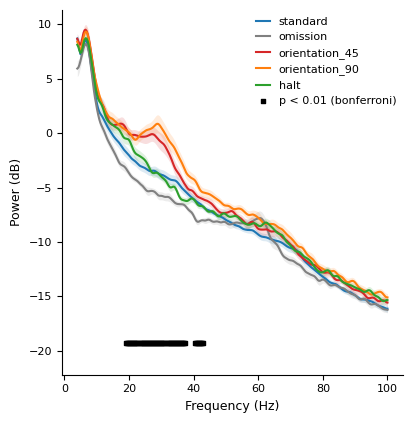

In [10]:
#@title Figure 1 panel D — VISp2/3 power spectrum by trial type
def psd_panel(ax, psd_by_condition, annotate_stats=True, legend=True):
    groups_db = {c: 10 * np.log10(v) for c, v in psd_by_condition.items()}

    sig_mask = np.zeros(len(FREQ), dtype=bool)
    if annotate_stats and len(groups_db) > 1:
        pvals = np.full(len(FREQ), np.nan)
        for f_idx in range(len(FREQ)):
            samples = [g[:, f_idx][~np.isnan(g[:, f_idx])] for g in groups_db.values()]
            if all(len(s) >= 2 for s in samples):
                try:
                    pvals[f_idx] = kruskal(*samples)[1]
                except ValueError:
                    pass
        valid = ~np.isnan(pvals)
        if valid.any():
            reject, *_ = multipletests(pvals[valid], alpha=ALPHA, method=CORRECTION_METHOD)
            sig_mask[valid] = reject
            print(f"{CORRECTION_METHOD}, alpha={ALPHA}: "
                  f"{sig_mask.sum()} / {valid.sum()} frequency bins significant")

    for cond in ODDBALL_CONDITIONS:
        if cond not in psd_by_condition:
            continue
        mean_db, sem_db = to_db(psd_by_condition[cond])
        ax.plot(FREQ, mean_db, lw=1.5, color=COND_COLORS[cond], label=cond)
        ax.fill_between(FREQ, mean_db - sem_db, mean_db + sem_db,
                        alpha=0.15, color=COND_COLORS[cond], lw=0)

    if sig_mask.any():
        lo, hi = ax.get_ylim()
        y_sig = lo - 0.05 * (hi - lo)
        ax.scatter(FREQ[sig_mask], np.full(sig_mask.sum(), y_sig),
                   marker="s", s=6, color="k",
                   label=f"p < {ALPHA} ({CORRECTION_METHOD})")
        ax.set_ylim(y_sig - 0.1 * (hi - lo), hi)

    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Power (dB)")
    if legend:
        ax.legend(frameon=False, loc="upper right", handlelength=1.2, borderaxespad=0.2)
    strip_spines(ax)


fig, ax = plt.subplots(figsize=(4.2, 4.3))
psd_panel(ax, psd_by_condition)
plt.tight_layout()
plt.show()

Hilbert envelope AUC over -0.183 to 0.183 s, referenced to -0.45 to -0.25 s baseline, 15 animals

        standard:  +0.740 ± 0.115 dB·s
        omission:  +0.104 ± 0.079 dB·s   vs standard: W=8, p=0.0015, p_holm=0.0031
  orientation_45:  +1.664 ± 0.184 dB·s   vs standard: W=1, p=0.0001, p_holm=0.0004
  orientation_90:  +2.019 ± 0.195 dB·s   vs standard: W=0, p=0.0001, p_holm=0.0002
            halt:  +0.638 ± 0.067 dB·s   vs standard: W=40, p=0.2769, p_holm=0.2769


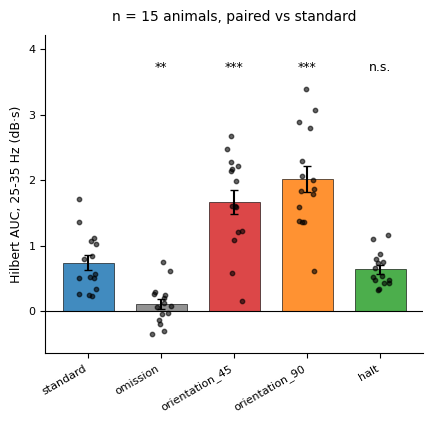

In [11]:
#@title Figure 1 panel E — Hilbert band-power AUC per animal, with paired tests
# Replaces the earlier PSD band boxplot. The AUC is taken from the Hilbert envelope rather than
# the PSD because the envelope is resolved in time, so the integral can be restricted to the
# stimulus itself instead of a window that also contains the neighbouring presentations at the
# fixed ~0.7 s ISI.
from scipy.stats import wilcoxon

# np.trapezoid is NumPy >= 2.0; np.trapz is the older name and is deprecated in 2.x. Binding it
# once here keeps the notebook running on both.
trapezoid = getattr(np, "trapezoid", None) or np.trapz

AUC_WINDOW      = (-STIM_DURATION / 2, STIM_DURATION / 2)   # the stimulus itself
AUC_BASELINE    = (-0.45, -0.25)     # trough between the preceding presentation and this one
AUC_REFERENCE   = "standard"         # every deviant is tested against this
AUC_CORRECTION  = "holm"


def hilbert_auc_by_animal(results_by_animal, conditions=None):
    """Area under the Hilbert band-power envelope during the stimulus, per animal.

    Each animal-condition trace is expressed in dB relative to its OWN pre-stimulus baseline
    before integrating. Absolute LFP power differs by orders of magnitude between animals for
    reasons unrelated to the stimulus (probe placement, impedance), so integrating raw power
    would make the group comparison a comparison of recording quality. Referencing each trace
    to its own baseline asks the only question that transfers across animals: how much did
    band power rise during the stimulus, relative to just before it.
    """
    conditions = conditions or ODDBALL_CONDITIONS
    animals = sorted(s for s in results_by_animal
                     if all(c in results_by_animal[s] for c in conditions))
    if not animals:
        return {}, []

    stim_mask = (T_VIEW >= AUC_WINDOW[0]) & (T_VIEW <= AUC_WINDOW[1])
    base_mask = (T_VIEW >= AUC_BASELINE[0]) & (T_VIEW <= AUC_BASELINE[1])

    out = {c: [] for c in conditions}
    for s in animals:
        for c in conditions:
            power = results_by_animal[s][c]["power"]
            baseline = power[base_mask].mean()
            db = 10 * np.log10(power / baseline)
            out[c].append(trapezoid(db[stim_mask], T_VIEW[stim_mask]))
    return {c: np.array(v) for c, v in out.items()}, animals


auc_by_condition, auc_animals = hilbert_auc_by_animal(results_by_animal)

print(f"Hilbert envelope AUC over {AUC_WINDOW[0]:.3f} to {AUC_WINDOW[1]:.3f} s, "
      f"referenced to {AUC_BASELINE[0]} to {AUC_BASELINE[1]} s baseline, "
      f"{len(auc_animals)} animals")

# Same animals in every condition, so the paired test applies (Wilcoxon signed-rank; the U test
# is the unpaired counterpart and would throw away the pairing).
auc_tests, raw_p, tested = {}, [], []
for cond in ODDBALL_CONDITIONS:
    if cond == AUC_REFERENCE or cond not in auc_by_condition:
        continue
    stat, p = wilcoxon(auc_by_condition[cond], auc_by_condition[AUC_REFERENCE])
    raw_p.append(p)
    tested.append(cond)
    auc_tests[cond] = {"stat": stat, "p_raw": p, "n": len(auc_animals)}

if raw_p:
    _, p_adj, _, _ = multipletests(raw_p, alpha=0.05, method=AUC_CORRECTION)
    for cond, p in zip(tested, p_adj):
        auc_tests[cond]["p_adj"] = p

print()
for cond in ODDBALL_CONDITIONS:
    if cond not in auc_by_condition:
        continue
    vals = auc_by_condition[cond]
    line = f"{cond:>16}: {vals.mean():+7.3f} ± {vals.std(ddof=1)/np.sqrt(len(vals)):.3f} dB·s"
    if cond in auc_tests:
        t = auc_tests[cond]
        line += (f"   vs {AUC_REFERENCE}: W={t['stat']:.0f}, "
                 f"p={t['p_raw']:.4f}, p_{AUC_CORRECTION}={t['p_adj']:.4f}")
    print(line)


def sig_stars(p):
    return "***" if p < 1e-3 else "**" if p < 1e-2 else "*" if p < 0.05 else "n.s."


def auc_bar_panel(ax, auc_by_condition, show_points=True):
    present = [c for c in ODDBALL_CONDITIONS if c in auc_by_condition]
    means = [auc_by_condition[c].mean() for c in present]
    sems = [auc_by_condition[c].std(ddof=1) / np.sqrt(len(auc_by_condition[c])) for c in present]
    colors = [COND_COLORS[c] for c in present]

    ax.bar(range(len(present)), means, yerr=sems, capsize=3, color=colors,
           edgecolor="k", linewidth=0.5, width=0.7, alpha=0.85)

    if show_points:
        rng = np.random.default_rng(0)
        for i, c in enumerate(present):
            vals = auc_by_condition[c]
            ax.scatter(np.full(len(vals), i) + rng.uniform(-0.13, 0.13, len(vals)), vals,
                       color="k", s=10, zorder=3, alpha=0.6)

    lo = min(min(auc_by_condition[c].min() for c in present), 0)
    hi = max(auc_by_condition[c].max() for c in present)
    span = hi - lo
    for i, c in enumerate(present):
        if c in auc_tests:
            ax.text(i, hi + 0.06 * span, sig_stars(auc_tests[c]["p_adj"]),
                    ha="center", va="bottom")
    ax.set_ylim(lo - 0.08 * span, hi + 0.22 * span)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(range(len(present)))
    ax.set_xticklabels(present, rotation=30, ha="right")
    ax.set_ylabel(f"Hilbert AUC, {BAND_HILBERT[0]}-{BAND_HILBERT[1]} Hz (dB·s)")
    strip_spines(ax)


fig, ax = plt.subplots(figsize=(4.4, 4.3))
auc_bar_panel(ax, auc_by_condition)
ax.set_title(f"n = {len(auc_animals)} animals, paired vs {AUC_REFERENCE}", pad=10)
plt.tight_layout()
plt.show()

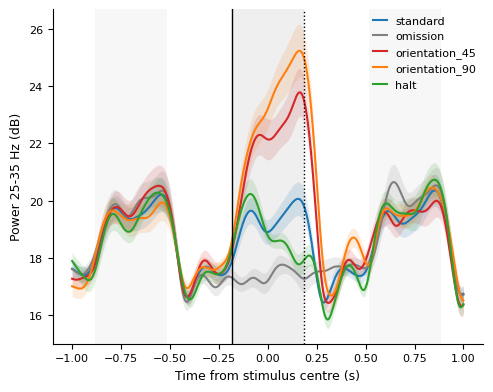

In [12]:
#@title Figure 1 panel C — band power over time, stimulus and neighbours visible
def power_psth_panel(ax, power_by_condition, show_neighbours=True, legend=True):
    half = STIM_DURATION / 2

    for cond in ODDBALL_CONDITIONS:
        if cond not in power_by_condition:
            continue
        mean_db, sem_db = to_db(power_by_condition[cond])
        ax.plot(T_VIEW, mean_db, lw=1.5, color=COND_COLORS[cond], label=cond)
        ax.fill_between(T_VIEW, mean_db - sem_db, mean_db + sem_db,
                        alpha=0.15, color=COND_COLORS[cond], lw=0)

    ax.axvspan(-half, half, color="grey", alpha=0.12, lw=0)
    ax.axvline(-half, color="k", lw=1.0)
    ax.axvline(half, color="k", lw=1.0, ls=":")

    # At a fixed ~0.7 s ISI the neighbouring presentations fall inside the window, which is why
    # the band rises on both sides of the central stimulus.
    if show_neighbours:
        for sign in (-1, 1):
            centre = sign * 0.7
            ax.axvspan(centre - half, centre + half, color="grey", alpha=0.06, lw=0)

    ax.set_xlabel("Time from stimulus centre (s)")
    ax.set_ylabel(f"Power {BAND_HILBERT[0]}-{BAND_HILBERT[1]} Hz (dB)")
    if legend:
        ax.legend(frameon=False, loc="upper right", handlelength=1.2, borderaxespad=0.2)
    strip_spines(ax)


fig, ax = plt.subplots(figsize=(5, 4))
power_psth_panel(ax, power_by_condition)
plt.tight_layout()
plt.show()

### Figure 1 panels A and B — single-trial example

Two cells: a search over VISp2/3 channels for the clearest orientation-change example, then the
plot. The search is deterministic, but once a good example is chosen it can be frozen by setting
`PIN_ELECTRODE_ID` and `PIN_WINDOW_START_IDX` below, which makes the panel independent of any
future change to the ranking.

In [13]:
#@title Figure 1 panels A/B · search — rank VISp2/3 channels by oddball band boost
WINDOW_SIZE     = 10          # presentations per candidate window
DEVIANT_TYPES   = {"omission", "orientation_45", "orientation_90", "halt"}
TARGET_ODDBALLS = {"orientation_45", "orientation_90"}
SEARCH_BAND     = BAND_HILBERT
SEG_PAD         = 2.0         # padding filtered then trimmed, so edges never reach the window

example_io, example_nwb = stream_nwb(DANDISET_ID, EXAMPLE_SESSION_PATH)
example_subject = str(example_nwb.subject.subject_id)
stim_df = (example_nwb.intervals[STIM_TABLE].to_dataframe()
           .sort_values("start_time").reset_index(drop=True))
example_channels = layer_channels(example_nwb, LAYER)
channel_map = lfp_channel_map(example_nwb)
print(f"Session {example_subject}: {len(example_channels)} {LAYER} channels with LFP")

# Windows containing exactly one deviant, so the example is not contaminated by a second one.
valid_windows = []
for i in range(len(stim_df) - WINDOW_SIZE + 1):
    types = stim_df.iloc[i:i + WINDOW_SIZE]["TrialType"].tolist()
    deviants = [j for j, tt in enumerate(types) if tt in DEVIANT_TYPES]
    if len(deviants) == 1:
        valid_windows.append({"start_idx": i, "oddball_position": deviants[0],
                              "oddball_type": types[deviants[0]]})

target_windows = [w for w in valid_windows if w["oddball_type"] in TARGET_ODDBALLS]
print(f"{len(target_windows)} isolated orientation-change windows")

candidates = []
for _, ch in example_channels.iterrows():
    series_name, col = channel_map[int(ch["electrode_id"])]
    es = example_nwb.processing["ecephys"]["LFP"].electrical_series[series_name]
    ts, fs = series_time_base(es)

    starts = [stim_df.iloc[w["start_idx"]]["start_time"] - SEG_PAD for w in target_windows]
    stops  = [stim_df.iloc[w["start_idx"] + WINDOW_SIZE - 1]["stop_time"] + SEG_PAD
              for w in target_windows]
    i0, i1 = np.searchsorted(ts, [min(starts), max(stops)])
    block, ts_block = es.data[i0:i1, col].astype(np.float64), ts[i0:i1]

    for w in target_windows:
        window = stim_df.iloc[w["start_idx"]: w["start_idx"] + WINDOW_SIZE]
        j0, j1 = np.searchsorted(ts_block, [window.iloc[0]["start_time"] - SEG_PAD,
                                            window.iloc[-1]["stop_time"] + SEG_PAD])
        if j1 - j0 < 20:
            continue
        seg, seg_t = block[j0:j1], ts_block[j0:j1]
        power = band_power(seg, fs, *SEARCH_BAND)

        core = (seg_t >= window.iloc[0]["start_time"]) & (seg_t <= window.iloc[-1]["stop_time"])
        power_core, t_core = power[core], seg_t[core]

        deviant = window.iloc[w["oddball_position"]]
        odd_mask = (t_core >= deviant["start_time"]) & (t_core <= deviant["stop_time"])
        if odd_mask.sum() < 5:
            continue

        standards = []
        for _, r in window[window["TrialType"] == "standard"].iterrows():
            m = (t_core >= r["start_time"]) & (t_core <= r["stop_time"])
            if m.sum() >= 5:
                standards.append(np.mean(power_core[m]))
        if not standards:
            continue

        baseline = float(np.mean(standards))
        candidates.append({
            "electrode_id": int(ch["electrode_id"]), "location": ch["location"],
            "window_start_idx": w["start_idx"], "oddball_type": w["oddball_type"],
            "odd_power": float(np.mean(power_core[odd_mask])), "baseline_power": baseline,
            "ratio": float(np.mean(power_core[odd_mask]) / baseline) if baseline > 0 else np.nan,
        })
    del block

candidate_df = pd.DataFrame(candidates).sort_values("ratio", ascending=False).reset_index(drop=True)
print(f"\nTop candidates by {SEARCH_BAND[0]}-{SEARCH_BAND[1]} Hz power ratio "
      f"(deviant / neighbouring standards):")
print(candidate_df.head(10).to_string(index=False))

ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/a7f50043-8883-4c0e-a956-2ff3e0f1b0ef/download/: 


Session 834687: 10 VISp2/3 channels with LFP
360 isolated orientation-change windows

Top candidates by 25-35 Hz power ratio (deviant / neighbouring standards):
 electrode_id location  window_start_idx   oddball_type   odd_power  baseline_power     ratio
         1422  VISp2/3              1733 orientation_90  952.034345       53.585896 17.766510
         1421  VISp2/3              1733 orientation_90 1091.747837       65.919895 16.561735
         1421  VISp2/3              1732 orientation_90 1091.742322       68.484497 15.941452
         1422  VISp2/3              1732 orientation_90  952.032175       63.485174 14.996134
         1420  VISp2/3              1732 orientation_90 1202.728212       81.918345 14.682038
         1420  VISp2/3              1733 orientation_90 1202.737786       83.433773 14.415479
         1421  VISp2/3               973 orientation_90 1026.630559       72.942986 14.074425
         1422  VISp2/3               973 orientation_90  823.653689       59.673476 13.

Using top-ranked example — pin it with PIN_ELECTRODE_ID = 1422, PIN_WINDOW_START_IDX = 1733


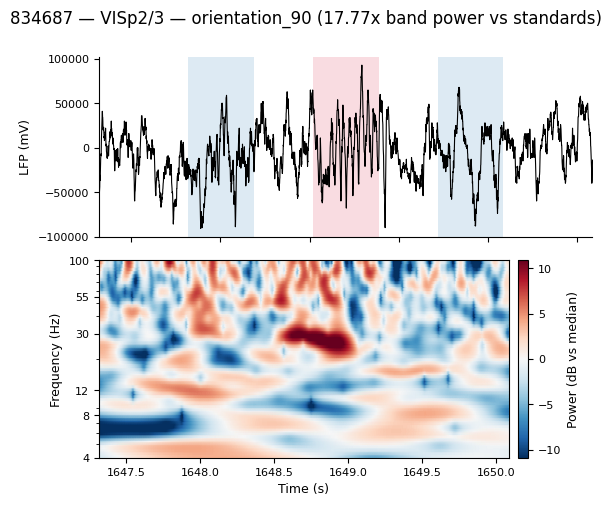

In [14]:
#@title Figure 1 panels A/B · plot — raw trace and wavelet spectrogram
PIN_ELECTRODE_ID     = None   # set both to freeze a chosen example
PIN_WINDOW_START_IDX = None

TARGET_POSITION = 1           # 0-indexed position of the deviant among shown stimuli
N_STIM_SHOWN    = 3           # deviant flanked by one standard either side
EX_PRE, EX_POST = 0.5, 0.5

if PIN_ELECTRODE_ID is not None and PIN_WINDOW_START_IDX is not None:
    match = candidate_df[(candidate_df["electrode_id"] == PIN_ELECTRODE_ID) &
                         (candidate_df["window_start_idx"] == PIN_WINDOW_START_IDX)]
    if match.empty:
        raise ValueError("Pinned example not found among candidates")
    best = match.iloc[0]
else:
    best = candidate_df.iloc[0]
    print(f"Using top-ranked example — pin it with "
          f"PIN_ELECTRODE_ID = {best['electrode_id']}, "
          f"PIN_WINDOW_START_IDX = {best['window_start_idx']}")

info = next(w for w in target_windows if w["start_idx"] == best["window_start_idx"])
deviant_idx = info["start_idx"] + info["oddball_position"]
window = stim_df.iloc[deviant_idx - TARGET_POSITION:
                      deviant_idx - TARGET_POSITION + N_STIM_SHOWN]

series_name, col = channel_map[int(best["electrode_id"])]
es = example_nwb.processing["ecephys"]["LFP"].electrical_series[series_name]
ts, fs = series_time_base(es)
i0, i1 = np.searchsorted(ts, [window.iloc[0]["start_time"] - EX_PRE,
                              window.iloc[-1]["stop_time"] + EX_POST])
raw, t = es.data[i0:i1, col].astype(np.float64), ts[i0:i1]

tf_power, frex = wavelet_tf(raw, fs, min_freq=FMIN, max_freq=FMAX, num_freq=60, n_cycles=6)
tf_db = 10 * np.log10(tf_power / np.median(tf_power, axis=1, keepdims=True))
tf_db = gaussian_filter(tf_db, sigma=(1.5, 5.0))


def example_panels(ax_raw, ax_tf):
    ax_raw.plot(t, raw * 1e3, color="k", lw=0.8)
    for _, r in window.iterrows():
        color = COND_COLORS["standard"] if r["TrialType"] == "standard" else "crimson"
        ax_raw.axvspan(r["start_time"], r["stop_time"], color=color, alpha=0.15, lw=0)
    ax_raw.set_ylabel("LFP (mV)")
    strip_spines(ax_raw)

    vmax = np.percentile(np.abs(tf_db), 98)
    mesh = ax_tf.pcolormesh(t, frex, tf_db, cmap="RdBu_r", shading="gouraud",
                            vmin=-vmax, vmax=vmax)
    ax_tf.set_yscale("log")
    ax_tf.set_yticks([4, 8, 12, 30, 55, 100])
    ax_tf.set_yticklabels([4, 8, 12, 30, 55, 100])
    ax_tf.set_ylabel("Frequency (Hz)")
    ax_tf.set_xlabel("Time (s)")
    return mesh


fig, (ax_raw, ax_tf) = plt.subplots(2, 1, figsize=(6, 5), sharex=True,
                                    gridspec_kw={"height_ratios": [1, 1.1]})
mesh = example_panels(ax_raw, ax_tf)
fig.colorbar(mesh, ax=ax_tf, label="Power (dB vs median)", pad=0.02)
fig.suptitle(f"{example_subject} — {best['location']} — {best['oddball_type']} "
             f"({best['ratio']:.2f}x band power vs standards)", y=1.0)
plt.tight_layout()
plt.show()

In [15]:
#@title Optional — oddball vs many-standards control (not in the assembled figure)
# Control block 1 presents each orientation with no preceding habituation, so it separates
# adaptation from genuine surprise. Requires INCLUDE_CONTROL = True at extraction time.
CONTROL_PAIRS = [("orientation_45", "control_45"), ("orientation_90", "control_90")]


def have_control():
    return any(c.startswith("control_") for r in results_by_animal.values() for c in r)


def control_panel(ax):
    mask = (FREQ >= BAND_PSD[0]) & (FREQ < BAND_PSD[1])
    positions, labels, data, colors = [], [], [], []

    for i, pair in enumerate(CONTROL_PAIRS):
        for j, cond in enumerate(pair):
            rows = [r[cond]["psd"] for r in results_by_animal.values() if cond in r]
            if not rows:
                continue
            positions.append(i * 2.5 + j)
            labels.append(cond)
            data.append(10 * np.log10(np.nanmean(np.array(rows)[:, mask], axis=1)))
            colors.append(COND_COLORS.get(cond, CONTROL_COLOR))

    bp = ax.boxplot(data, positions=positions, patch_artist=True, widths=0.6,
                    showfliers=False, medianprops=dict(color="k", lw=1.2))
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.5)
        patch.set_edgecolor(color)

    rng = np.random.default_rng(0)
    for pos, vals, color in zip(positions, data, colors):
        ax.scatter(pos + rng.uniform(-0.12, 0.12, size=len(vals)), vals, color=color,
                   edgecolor="k", linewidth=0.4, s=20, zorder=3)

    ax.set_xticks(positions)
    ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_ylabel(f"Power {BAND_PSD[0]}-{BAND_PSD[1]} Hz (dB)")
    strip_spines(ax)


if not have_control():
    print("No control conditions in cache. "
          "Set INCLUDE_CONTROL = True, delete ./cache, and re-run extraction.")
else:
    fig, ax = plt.subplots(figsize=(4.6, 4.3))
    control_panel(ax)
    plt.tight_layout()
    plt.show()

No control conditions in cache. Set INCLUDE_CONTROL = True, delete ./cache, and re-run extraction.


## 5 · Figure 1, assembled

bonferroni, alpha=0.01: 67 / 300 frequency bins significant
Saved ./figures/visp_l23_showcase.png
Saved ./figures/visp_l23_showcase.pdf


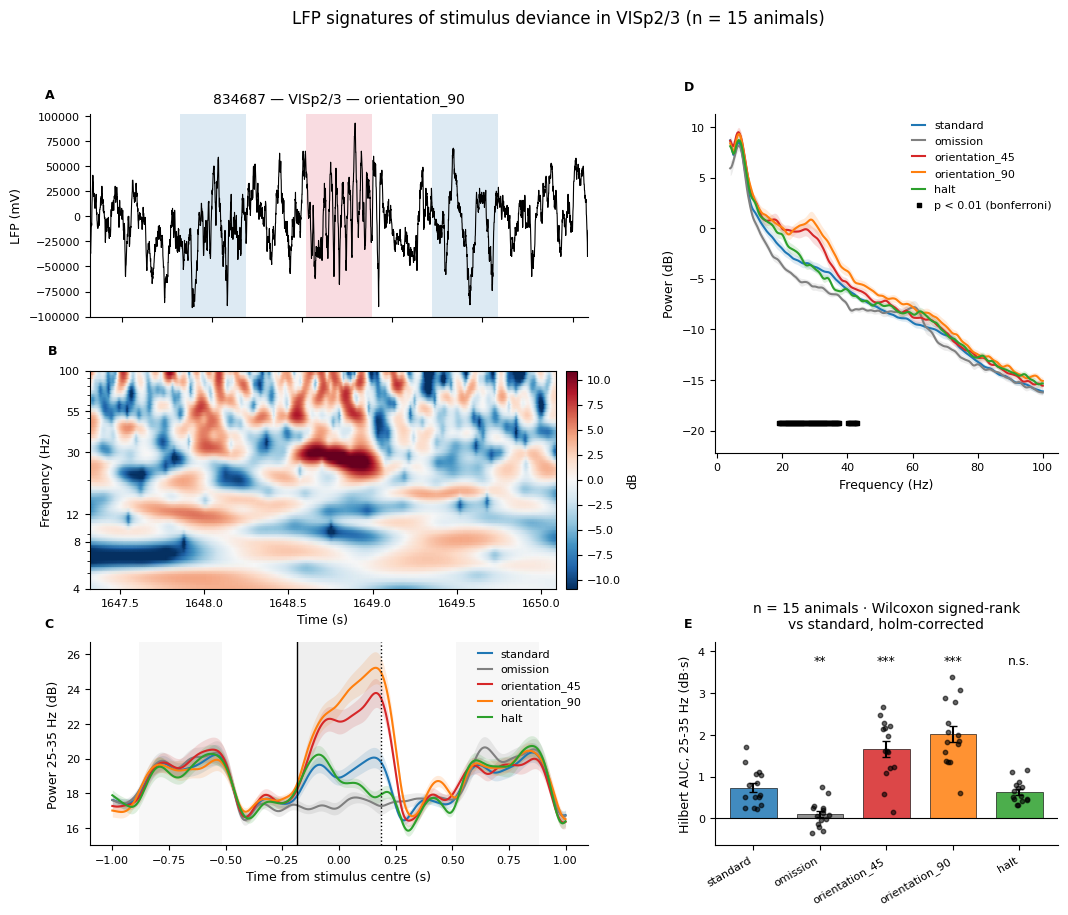

In [16]:
#@title Figure 1 · compose and save
# Left column walks through one example (raw LFP, its time-frequency content, and the band-power
# time course); right column is the population summary (spectrum by trial type, and the Hilbert
# AUC during the stimulus).
#
# No stimulus icons here: imshow with an explicit extent on a sharex axis resets the shared
# x-limits to that image, which collapses the example window down to a single presentation.
# Orientation icons are easier to add post hoc in a vector editor anyway.

fig = plt.figure(figsize=(12.5, 9.5))
gs = fig.add_gridspec(6, 2, height_ratios=[1, 1, 1.1, 1.1, 1, 1],
                      width_ratios=[1.45, 1], hspace=0.7, wspace=0.3)

# ── Left column: one example ────────────────────────────────────────────────
ax_raw = fig.add_subplot(gs[0:2, 0])
ax_tf = fig.add_subplot(gs[2:4, 0], sharex=ax_raw)
mesh = example_panels(ax_raw, ax_tf)
ax_raw.tick_params(labelbottom=False)
ax_raw.set_title(f"{example_subject} — {best['location']} — {best['oddball_type']}", pad=8)

cbar = fig.colorbar(mesh, ax=ax_tf, fraction=0.045, pad=0.02)
cbar.set_label("dB")

ax_psth = fig.add_subplot(gs[4:6, 0])
power_psth_panel(ax_psth, power_by_condition)

# ── Right column: population ────────────────────────────────────────────────
ax_psd = fig.add_subplot(gs[0:3, 1])
psd_panel(ax_psd, psd_by_condition)

ax_auc = fig.add_subplot(gs[4:6, 1])
auc_bar_panel(ax_auc, auc_by_condition)
ax_auc.set_title(f"n = {len(auc_animals)} animals · Wilcoxon signed-rank\nvs {AUC_REFERENCE}, {AUC_CORRECTION}-corrected", pad=10)

for ax, letter in [(ax_raw, "A"), (ax_tf, "B"), (ax_psth, "C"),
                   (ax_psd, "D"), (ax_auc, "E")]:
    ax.text(-0.09, 1.06, letter, transform=ax.transAxes,
            fontweight="bold", va="bottom", ha="left")

n_animals = len(results_by_animal)
fig.suptitle(f"LFP signatures of stimulus deviance in {LAYER} (n = {n_animals} animals)", y=0.99)

for ext in ("png", "pdf"):
    out = os.path.join(FIGURE_DIR, f"visp_l23_showcase.{ext}")
    fig.savefig(out, dpi=300, bbox_inches="tight")
    print(f"Saved {out}")
plt.show()

In [17]:
#@title Figure 1 provenance
print(f"Dandiset      : {DANDISET_ID} (draft)")
print(f"Sessions      : {len(STANDARD_SESSION_PATHS)} frozen")
print(f"Animals used  : {len(results_by_animal)}")
print(f"Region        : {LAYER}")
print(f"Window        : -{PRE_PAD} to +{POST_PAD} s around stimulus centre "
      f"(+{EDGE_PAD} s discarded edges)")
print(f"PSD taper     : Gaussian, FWHM {TAPER_FWHM} s")
print(f"Bands         : PSD summary {BAND_PSD} Hz, Hilbert {BAND_HILBERT} Hz")
print(f"Statistics    : Kruskal-Wallis per frequency bin, {CORRECTION_METHOD}, alpha {ALPHA}")
print(f"Trials/session: {N_TRIALS_DEFAULT} per deviant, {N_TRIALS['standard']} standards "
      f"(seed {RNG_SEED})")
print(f"Control block : {'included' if INCLUDE_CONTROL else 'not included'}")
print()
for cond in ODDBALL_CONDITIONS:
    if cond in psd_by_condition:
        print(f"  {cond:>16}: n = {len(psd_by_condition[cond])} animals")

import matplotlib, scipy, pynwb
print()
print(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | "
      f"matplotlib {matplotlib.__version__} | pynwb {pynwb.__version__}")

Dandiset      : 001637 (draft)
Sessions      : 15 frozen
Animals used  : 15
Region        : VISp2/3
Window        : -1.0 to +1.0 s around stimulus centre (+0.5 s discarded edges)
PSD taper     : Gaussian, FWHM 0.35 s
Bands         : PSD summary (15, 35) Hz, Hilbert (25, 35) Hz
Statistics    : Kruskal-Wallis per frequency bin, bonferroni, alpha 0.01
Trials/session: 35 per deviant, 200 standards (seed 42)
Control block : not included

          standard: n = 15 animals
          omission: n = 15 animals
    orientation_45: n = 15 animals
    orientation_90: n = 15 animals
              halt: n = 15 animals

numpy 2.1.3 | pandas 2.2.3 | scipy 1.16.3 | matplotlib 3.10.0 | pynwb 4.1.0


In [18]:
#@title Release the example session handle
try:
    example_io.close()
    print("Closed example session")
except Exception as e:
    print(f"Nothing to close: {e}")

Closed example session


## 6 · Figure 2 — spike-field coupling of photo-identified interneurons

Every session in this dandiset is **SST-IRES-Cre;Ai32**, so ChR2 sits in somatostatin
interneurons, and every session runs an optotagging block. That makes it possible to ask a
question the LFP alone cannot answer: *which cell type is coupled to the 25-35 Hz rhythm that
Figure 1 showed is elevated during orientation-change oddballs?*

The section proceeds in four steps:

1. **Place the units.** These files are SpikeInterface exports with no `peak_channel_id`, so
   each unit's peak channel is recovered from its `electrodes` region.
2. **Tag them.** Units are screened against the optotagging blocks. The `5 hz` and `40 hz`
   pulse trains are the criterion; `raised_cosine` is reported but not trusted, because ChR2
   desensitises under a slow 1 s ramp and a whole-window rate ratio understates the response.
3. **Measure phase coupling.** Each unit's phase reference is its *nearest neighbour* LFP
   channel, never its own peak channel — a spike's broadband energy leaks into the filtered
   band on the channel that recorded it, which inflates coupling artificially.
4. **Compare against a control population.** For every session, an equal-times-two random
   sample of VISp units that were *not* directly light-activated. Network-modulated cells stay
   in the control pool on purpose: being suppressed downstream of the tagged interneurons is a
   circuit consequence, not evidence of ChR2 expression.

## 6.1 · Placing and screening units

Helpers shared by every cell below, defined once. `unit_peak_rows` returns a note describing
which route it used, because the mapping is inferred from column semantics rather than
documented — and it refuses to guess rather than returning wrong layers.

In [19]:
#@title Unit helpers — location, waveform, light response
from scipy.stats import wilcoxon


def decode(x):
    return x.decode() if isinstance(x, bytes) else str(x)


def is_visp(location):
    """VISp and its layers. Prefix matching on "VISp" would also swallow VISpm and VISpor,
    which are different visual areas, not layers of V1."""
    return re.match(r"^VISp(\d|$)", str(location)) is not None


def read_scalar_column(table, name):
    """Column values without touching ragged columns such as spike_times, which would pull
    every spike of every unit over the network."""
    col = table[name]
    data = getattr(col, "data", None)
    if data is None:
        return None
    try:
        return np.asarray(data[:])
    except Exception:
        return None


def unit_electrode_rows(units):
    """Electrode-table row indices spanned by each unit's waveform."""
    if "electrodes" not in units.colnames:
        return None
    col = units["electrodes"]
    target = getattr(col, "target", None)          # DynamicTableRegion
    if target is None:
        return None
    rows = np.asarray(target.data[:])
    ends = np.asarray(col.data[:])
    starts = np.concatenate([[0], ends[:-1]])
    return [rows[s:e] for s, e in zip(starts, ends)]


def unit_peak_rows(units):
    """One electrode-table row per unit: its peak channel.

    In these files the `electrodes` region spans a whole probe and `extremum_channel_index`
    indexes into that list. Returns (rows, note); rows is None when the mapping cannot be
    established, rather than falling back to something that would silently mislabel layers.
    """
    per_unit = unit_electrode_rows(units)
    if per_unit is None:
        return None, "no electrodes region on units"

    widths = np.array([len(r) for r in per_unit])
    extremum = read_scalar_column(units, "extremum_channel_index")

    if extremum is not None and len(extremum) == len(per_unit):
        in_range = np.array([0 <= int(e) < len(r) for e, r in zip(extremum, per_unit)])
        if in_range.all():
            peak = np.array([r[int(e)] for e, r in zip(extremum, per_unit)])
            return peak, ("extremum_channel_index into electrodes region "
                          f"(waveform spans {widths.min()}-{widths.max()} channels)")
        note = (f"extremum_channel_index out of range for {(~in_range).sum()} units "
                f"(range {extremum.min()}-{extremum.max()}, spans {widths.min()}-{widths.max()})")
    else:
        note = "extremum_channel_index unavailable"

    if (widths == 1).all():
        return np.array([r[0] for r in per_unit]), f"single-channel regions; {note}"
    return None, note


def unit_locations_from_rows(nwb, peak_rows):
    """Brain-region label per unit, given its peak electrode rows."""
    locations = nwb.electrodes.to_dataframe()["location"].map(decode).to_numpy()
    valid = (peak_rows >= 0) & (peak_rows < len(locations))
    out = np.full(len(peak_rows), "unknown", dtype=object)
    out[valid] = locations[peak_rows[valid]]
    return out


def check_probe_consistency(nwb, peak_rows, units):
    """A unit's peak electrode should sit on the probe it was recorded from. With a 480-channel
    region spanning the whole probe, this is the check that the index means what we assume."""
    edf = nwb.electrodes.to_dataframe()
    group_col = next((c for c in ("group_name", "probe_name") if c in edf.columns), None)
    device = read_scalar_column(units, "device_name")
    if group_col is None or device is None:
        return "cannot verify: no group/device columns"
    groups = edf[group_col].map(decode).to_numpy()
    match = np.array([decode(d).lower() == str(g).lower()
                      for d, g in zip(device, groups[peak_rows])])
    return f"peak channel on the unit's own probe for {match.mean():.1%} ({match.sum()}/{len(match)})"


def window_counts(spikes, onsets, window):
    """Spikes per trial inside a window relative to onset. Assumes sorted spike times."""
    lo = np.searchsorted(spikes, onsets + window[0])
    hi = np.searchsorted(spikes, onsets + window[1])
    return (hi - lo).astype(float)

In [20]:
#@title Optotagging configuration and screen
# The three optotagging blocks are not labelled "opto" anywhere in the file; they are named
# after their waveform. Zebra_presentations is a visual movie block, not light.
OPTO_TABLES = {
    "raised_cosine": "raised_cosine_presentations",   # 1 s half-cosine ramp
    "pulse_5hz":     "5 hz pulse train_presentations",  # 10 ms pulses
    "pulse_40hz":    "40 hz pulse train_presentations", # 6 ms pulses
}
# Trains re-depolarise the cell on every pulse; the slow ramp lets ChR2 desensitise, so a
# whole-window rate ratio understates it. Only the trains define tagging.
TRUSTED_TAG_CONDITIONS = ("pulse_5hz", "pulse_40hz")

QC_COLUMN       = "default_qc"     # None keeps every unit
BASELINE_WINDOW = (-0.6, -0.1)     # trials repeat every ~1.9 s, so this clears the previous one
EVOKED_WINDOW   = (0.0, 1.0)       # the light is on for exactly 1 s
PSTH_WINDOW     = (-0.5, 1.5)
PSTH_BIN        = 0.005
ALPHA_TAG       = 0.01
MIN_RATIO       = 2.0              # evoked / baseline required to call a unit activated

PSTH_EDGES = np.arange(PSTH_WINDOW[0], PSTH_WINDOW[1] + PSTH_BIN, PSTH_BIN)
PSTH_TIME  = PSTH_EDGES[:-1] + PSTH_BIN / 2


def trial_psth(spikes, onsets):
    lo = np.searchsorted(spikes, onsets + PSTH_EDGES[0])
    hi = np.searchsorted(spikes, onsets + PSTH_EDGES[-1])
    chunks = [spikes[a:b] - o for a, b, o in zip(lo, hi, onsets) if b > a]
    if not chunks:
        return np.zeros(len(PSTH_TIME))
    counts, _ = np.histogram(np.concatenate(chunks), bins=PSTH_EDGES)
    return counts / (len(onsets) * PSTH_BIN)


def opto_onsets(nwb):
    """Trial onsets per optotagging condition."""
    out = {}
    for cond, table in OPTO_TABLES.items():
        if table in nwb.intervals:
            df = nwb.intervals[table].to_dataframe().sort_values("start_time")
            out[cond] = df["start_time"].to_numpy()
    return out


def candidate_units(nwb, peak_rows):
    """VISp units passing QC — the pool that gets screened for light response."""
    locations = unit_locations_from_rows(nwb, peak_rows)
    keep = np.array([is_visp(l) for l in locations])
    units = nwb.units
    if QC_COLUMN and QC_COLUMN in units.colnames:
        qc = read_scalar_column(units, QC_COLUMN)
        if qc is not None:
            keep &= np.array([str(v).lower() in ("true", "1", "good") or v is True for v in qc])
    return np.flatnonzero(keep), locations


def screen_for_light_response(nwb, unit_idx, keep_psth=False, progress_every=50):
    """Per-(unit, condition) light response.

    Returns a long-form frame with FDR-corrected p across units within each condition, plus
    optionally the PSTHs (kept for the tagging panel of the assembled figure).
    """
    onsets_by_cond = opto_onsets(nwb)
    if not onsets_by_cond:
        return pd.DataFrame(), {}

    spike_col = nwb.units["spike_times"]
    unit_names = read_scalar_column(nwb.units, "unit_name")
    rows, psths = [], {}

    for n, i in enumerate(unit_idx, start=1):
        spikes = np.sort(np.asarray(spike_col[int(i)]))
        if progress_every and (n % progress_every == 0 or n == len(unit_idx)):
            print(f"      {n}/{len(unit_idx)} units screened")
        for cond, onsets in onsets_by_cond.items():
            base = window_counts(spikes, onsets, BASELINE_WINDOW) / (BASELINE_WINDOW[1] - BASELINE_WINDOW[0])
            evoked = window_counts(spikes, onsets, EVOKED_WINDOW) / (EVOKED_WINDOW[1] - EVOKED_WINDOW[0])
            base_hz, evoked_hz = base.mean(), evoked.mean()
            if np.allclose(base, evoked):
                p = 1.0
            else:
                try:
                    p = wilcoxon(evoked, base)[1]
                except ValueError:
                    p = 1.0
            rows.append({
                "unit_index": int(i),
                "unit_name": decode(unit_names[i]) if unit_names is not None else str(i),
                "condition": cond, "n_spikes": len(spikes),
                "baseline_hz": base_hz, "evoked_hz": evoked_hz,
                "ratio": evoked_hz / base_hz if base_hz > 0 else np.inf, "p": p,
            })
            if keep_psth:
                psths[(int(i), cond)] = trial_psth(spikes, onsets)

    df = pd.DataFrame(rows)
    df["p_adj"] = np.nan
    for cond, grp in df.groupby("condition"):
        valid = grp["p"].notna()
        if valid.sum():
            _, adj, _, _ = multipletests(grp.loc[valid, "p"], alpha=ALPHA_TAG, method="fdr_bh")
            df.loc[grp.index[valid], "p_adj"] = adj

    # A ratio of inf means the unit had zero baseline spikes, which passes any ratio threshold
    # trivially without carrying evidence, so it is not allowed to count as activation.
    finite_ratio = np.isfinite(df["ratio"])
    df["activated"] = (df["p_adj"] < ALPHA_TAG) & (df["ratio"] >= MIN_RATIO) & finite_ratio
    df["suppressed"] = (df["p_adj"] < ALPHA_TAG) & (df["evoked_hz"] < df["baseline_hz"])
    return df, psths


def tagged_from_screen(screen, conditions=TRUSTED_TAG_CONDITIONS):
    """Units activated by at least one trusted (pulse-train) condition."""
    hit = screen[screen["condition"].isin(conditions) & screen["activated"]]
    return sorted(hit["unit_index"].unique())

In [21]:
#@title Run the tagging screen on the example session
TAG_SESSION = STANDARD_SESSION_PATHS[0]

io, nwb = stream_nwb(DANDISET_ID, TAG_SESSION)
try:
    tag_subject = str(nwb.subject.subject_id)
    units = nwb.units
    peak_rows, map_note = unit_peak_rows(units)
    if peak_rows is None:
        raise RuntimeError(f"cannot place units: {map_note}")

    print(f"Session {tag_subject} — {len(units)} units")
    print(f"  genotype: {getattr(nwb.subject, 'genotype', 'unknown')}")
    print(f"  location mapping: {map_note}")
    print(f"  sanity check: {check_probe_consistency(nwb, peak_rows, units)}")

    screened_idx, all_locations = candidate_units(nwb, peak_rows)
    print(f"  VISp units passing {QC_COLUMN}: {len(screened_idx)}")
    for cond, onsets in opto_onsets(nwb).items():
        print(f"  {cond}: {len(onsets)} trials")

    opto_screen, psths = screen_for_light_response(nwb, screened_idx, keep_psth=True)
    opto_screen["location"] = opto_screen["unit_index"].map(
        lambda i: all_locations[i])
finally:
    io.close()

tagged_units = tagged_from_screen(opto_screen)

print("\n" + "=" * 78)
for cond in OPTO_TABLES:
    sub = opto_screen[opto_screen["condition"] == cond]
    if len(sub):
        print(f"{cond:>14}: {sub['activated'].sum():3d} activated, "
              f"{sub['suppressed'].sum():3d} suppressed of {len(sub)}")
print(f"\nTagged (activated by {' or '.join(TRUSTED_TAG_CONDITIONS)}): {len(tagged_units)} units")
if tagged_units:
    print(opto_screen[opto_screen["unit_index"].isin(tagged_units)]
          .pivot_table(index=["unit_index", "location"], columns="condition", values="ratio")
          .round(2).to_string())

ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/a7f50043-8883-4c0e-a956-2ff3e0f1b0ef/download/: 


Session 834687 — 3133 units
  genotype: Sst-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt
  location mapping: extremum_channel_index into electrodes region (waveform spans 480-480 channels)
  sanity check: peak channel on the unit's own probe for 100.0% (3133/3133)
  VISp units passing default_qc: 147
  raised_cosine: 150 trials
  pulse_5hz: 150 trials
  pulse_40hz: 150 trials
      50/147 units screened
      100/147 units screened
      147/147 units screened

 raised_cosine:   5 activated, 112 suppressed of 147
     pulse_5hz:   5 activated, 102 suppressed of 147
    pulse_40hz:   8 activated, 120 suppressed of 147

Tagged (activated by pulse_5hz or pulse_40hz): 9 units
condition            pulse_40hz  pulse_5hz  raised_cosine
unit_index location                                      
1226       VISp6b         46.88       4.20           0.33
1277       VISp1          82.04      15.06           0.34
1300       VISp4          16.68       5.71          11.46
1354       VISp2/3         0.04 

## 6.2 · Phase reference

Two choices matter here and both are deliberate.

**Never the unit's own channel.** A spike's broadband energy leaks into the 25-35 Hz band on
the channel that recorded it, so measuring a unit's coupling against its own peak channel
inflates it — the classic bleed-through confound in the spike-field literature. Each unit is
referenced to its nearest *other* LFP channel on the same probe instead.

**One channel, not an average of the layer.** Averaging band-filtered traces across VISp2/3 is
equivalent to averaging their analytic signals, which is fine when the channels share a phase
but produces an unstable, physically meaningless phase when they do not — and spatial coherence
length shrinks as frequency rises, so that assumption is least safe in exactly this band. A
single neighbour channel avoids the question entirely, at the cost of some SNR.

Phase is computed over the task span only. A session also contains RF mapping, control blocks,
the opto block and spontaneous activity, and filtering all of it is what makes this step
expensive in memory for no benefit.

In [22]:
#@title Phase helpers — nearest neighbour, windowed Hilbert, PPC
SFC_BAND  = BAND_HILBERT     # 25-35 Hz, the band Figure 1 showed is oddball-specific
EVENT_PAD = 2.0              # signal filtered either side of the task span, then discarded

POSITION_COLUMN_SETS = [
    ("x", "y", "z"),
    ("probe_horizontal_position", "probe_vertical_position"),
    ("rel_x", "rel_y"),
]


def find_position_columns(edf):
    for cols in POSITION_COLUMN_SETS:
        if all(c in edf.columns for c in cols):
            return cols
    return None


def nearest_neighbor_channel(edf, peak_row, channel_map, group_col):
    """Closest *other* LFP channel on the same probe. Excluding the peak channel is the point:
    see the note above on spike bleed-through."""
    same_probe = (edf.index[edf[group_col] == edf.loc[peak_row, group_col]]
                  if group_col else edf.index)
    candidates = [i for i in same_probe if i in channel_map and i != peak_row]
    if not candidates:
        return None, "no other LFP channel on this probe"

    pos_cols = find_position_columns(edf)
    if pos_cols is not None:
        p0 = edf.loc[peak_row, list(pos_cols)].to_numpy(dtype=float)
        pts = edf.loc[candidates, list(pos_cols)].to_numpy(dtype=float)
        d = np.linalg.norm(pts - p0, axis=1)
        return candidates[int(np.argmin(d))], f"nearest by position, distance {d.min():.1f}"

    return (min(candidates, key=lambda i: abs(i - peak_row)),
            "no position columns; nearest by table row (assumes depth ordering)")


def band_phase_windowed(es, lo, hi, t_lo, t_hi, col=0):
    """Bandpass + Hilbert over [t_lo, t_hi] only, not the whole multi-block recording."""
    ts, fs = series_time_base(es)
    i0, i1 = np.searchsorted(ts, [t_lo, t_hi])
    trace = (es.data[i0:i1, col] if es.data.ndim > 1 else es.data[i0:i1]).astype(np.float64)
    b, a = butter(4, [lo / (fs / 2), hi / (fs / 2)], btype="band")
    return ts[i0:i1], np.angle(hilbert(filtfilt(b, a, trace)))


def phase_source(nwb, u, peak_rows, edf, channel_map, group_col,
                 neighbor_cache, phase_cache, t_lo, t_hi):
    """(ts, phase) for a unit's reference channel.

    Cached by the *neighbour* channel, which is the thing actually filtered — several units
    with different peak channels often share one neighbour, and keying by peak channel would
    recompute the same Hilbert transform for each of them.
    """
    peak = int(peak_rows[u])
    if peak not in neighbor_cache:
        neighbor_cache[peak] = nearest_neighbor_channel(edf, peak, channel_map, group_col)
    neighbor, note = neighbor_cache[peak]
    if neighbor is None:
        return None, note
    if neighbor not in phase_cache:
        series_name, col = channel_map[neighbor]
        es = nwb.processing["ecephys"]["LFP"].electrical_series[series_name]
        phase_cache[neighbor] = band_phase_windowed(es, *SFC_BAND, t_lo, t_hi, col=col)
    return phase_cache[neighbor], f"ch {neighbor} ({note})"


def phase_at(ts, phase, times):
    """Nearest-sample lookup. Angles are not interpolated: interpolating across the +/-pi wrap
    is wrong, and at ~1250 Hz the nearest sample is already within ~0.8 ms."""
    idx = np.clip(np.searchsorted(ts, times), 0, len(ts) - 1)
    left = np.clip(idx - 1, 0, len(ts) - 1)
    use_left = np.abs(ts[left] - times) < np.abs(ts[idx] - times)
    return phase[np.where(use_left, left, idx)]


def ppc(phases):
    """Pairwise phase consistency, (n*R^2 - 1)/(n - 1).

    Preferred over the raw resultant length because it is unbiased by spike count, and spike
    counts differ several-fold between standards and deviants here.
    """
    n = len(phases)
    if n < 2:
        return np.nan, np.nan, np.nan
    z = np.mean(np.exp(1j * phases))
    R = np.abs(z)
    return (n * R ** 2 - 1) / (n - 1), R, np.angle(z)


def spike_phases_in_windows(spikes, windows, ts, phase):
    """Phase at every spike inside any [start, stop) window, plus its window index."""
    out_phase, out_trial = [], []
    for i, (t0, t1) in enumerate(windows):
        lo, hi = np.searchsorted(spikes, [t0, t1])
        if hi <= lo:
            continue
        out_phase.append(phase_at(ts, phase, spikes[lo:hi]))
        out_trial.append(np.full(hi - lo, i))
    if not out_phase:
        return np.array([]), np.array([], dtype=int)
    return np.concatenate(out_phase), np.concatenate(out_trial)


def permutation_ppc(spikes, windows, ts, phase, observed, n_perm=200, rng=None):
    """Null by per-trial circular shift: each trial's spikes are rotated within that trial's own
    duration. This preserves spikes-per-trial and the phase signal's own autocorrelation, so it
    tests coupling rather than merely non-uniformity produced by a stimulus-locked response."""
    rng = np.random.default_rng(0) if rng is None else rng
    windows = np.asarray(windows)
    durations = windows[:, 1] - windows[:, 0]
    null = np.full(n_perm, np.nan)
    for p in range(n_perm):
        chunks = []
        for i, (t0, t1) in enumerate(windows):
            lo, hi = np.searchsorted(spikes, [t0, t1])
            if hi <= lo:
                continue
            shifted = t0 + (spikes[lo:hi] - t0 + rng.uniform(0, durations[i])) % durations[i]
            chunks.append(phase_at(ts, phase, shifted))
        if chunks:
            null[p], _, _ = ppc(np.concatenate(chunks))
    valid = null[~np.isnan(null)]
    if len(valid) == 0 or np.isnan(observed):
        return np.nan
    return (np.sum(valid >= observed) + 1) / (len(valid) + 1)


def task_span(events):
    return (events["start_time"].min() - EVENT_PAD, events["stop_time"].max() + EVENT_PAD)


def windows_by_condition(events):
    return {c: events.loc[events["condition"] == c, ["start_time", "stop_time"]].to_numpy()
            for c in ODDBALL_CONDITIONS}

In [23]:
#@title Per-unit SFC in the example session
SFC_N_PERM = 200

io, nwb = stream_nwb(DANDISET_ID, TAG_SESSION)
try:
    units = nwb.units
    peak_rows, _ = unit_peak_rows(units)
    edf = nwb.electrodes.to_dataframe()
    group_col = next((c for c in ("group_name", "probe_name") if c in edf.columns), None)
    channel_map = lfp_channel_map(nwb)
    spike_col = units["spike_times"]
    unit_names = read_scalar_column(units, "unit_name")

    events = build_events(nwb, include_control=False)
    windows_by_cond = windows_by_condition(events)
    t_lo, t_hi = task_span(events)
    print(f"{len(tagged_units)} tagged units | filtering {t_hi - t_lo:.0f} s of task span")
    for c, w in windows_by_cond.items():
        print(f"  {c}: {len(w)} presentations")

    neighbor_cache, phase_cache = {}, {}
    rows, spike_phase_store = [], {}

    for u in tagged_units:
        src, note = phase_source(nwb, u, peak_rows, edf, channel_map, group_col,
                                 neighbor_cache, phase_cache, t_lo, t_hi)
        if src is None:
            print(f"  unit {u}: {note} -- skipped")
            continue
        ts, phase = src
        spikes = np.sort(np.asarray(spike_col[int(u)]))
        uname = decode(unit_names[u]) if unit_names is not None else str(u)
        print(f"  unit {u} ({uname}): peak ch {int(peak_rows[u])} -> {note}")

        for cond, windows in windows_by_cond.items():
            if len(windows) == 0:
                continue
            phases, _ = spike_phases_in_windows(spikes, windows, ts, phase)
            val, R, pref = ppc(phases)
            p_perm = (permutation_ppc(spikes, windows, ts, phase, val, n_perm=SFC_N_PERM)
                      if len(phases) >= 2 else np.nan)
            rows.append({"unit_index": u, "unit_name": uname, "condition": cond,
                         "n_spikes": len(phases), "ppc": val, "resultant_length": R,
                         "preferred_phase_deg": np.degrees(pref) if not np.isnan(pref) else np.nan,
                         "p_perm": p_perm})
            spike_phase_store[(u, cond)] = phases

    sfc_results = pd.DataFrame(rows)
    print(f"  used {len(phase_cache)} distinct reference channels for {len(tagged_units)} units")
finally:
    io.close()

print("\n" + "=" * 78)
if sfc_results.empty:
    print("No tagged units with usable spikes.")
else:
    print(sfc_results.round(3).to_string(index=False))
    sig = sfc_results[sfc_results["p_perm"] < 0.05]
    print(f"\n{len(sig)} / {len(sfc_results)} unit-condition pairs significant at p<0.05 "
          f"({SFC_N_PERM} shifts; floor is p={1/(SFC_N_PERM+1):.3f})")

ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/a7f50043-8883-4c0e-a956-2ff3e0f1b0ef/download/: 


9 tagged units | filtering 1579 s of task span
  standard: 200 presentations
  omission: 35 presentations
  orientation_45: 35 presentations
  orientation_90: 35 presentations
  halt: 35 presentations
  unit 1226 (11c73cfa-0e61-469c-af9a-4317658dcaf2): peak ch 1202 -> ch 1404 (nearest by position, distance 25.0)
  unit 1277 (885b8194-8055-4f0b-9527-4a010b7b0935): peak ch 1287 -> ch 1426 (nearest by position, distance 0.0)
  unit 1300 (795fcdc3-a532-4f42-adb7-a4f55986e467): peak ch 1240 -> ch 1414 (nearest by position, distance 0.0)
  unit 1354 (94353922-e171-4bc1-99eb-c804dc7080f3): peak ch 1270 -> ch 1421 (nearest by position, distance 25.0)
  unit 1499 (f482ca55-9025-40b8-ab29-21a161c0c173): peak ch 1756 -> ch 1903 (nearest by position, distance 0.0)
  unit 1870 (c55c9ea2-875d-4ea0-a25b-c913ce96cae2): peak ch 1690 -> ch 1886 (nearest by position, distance 35.4)
  unit 1893 (37855ec0-cee1-45e1-9693-82b654a55cab): peak ch 1704 -> ch 1890 (nearest by position, distance 0.0)
  unit 1933 

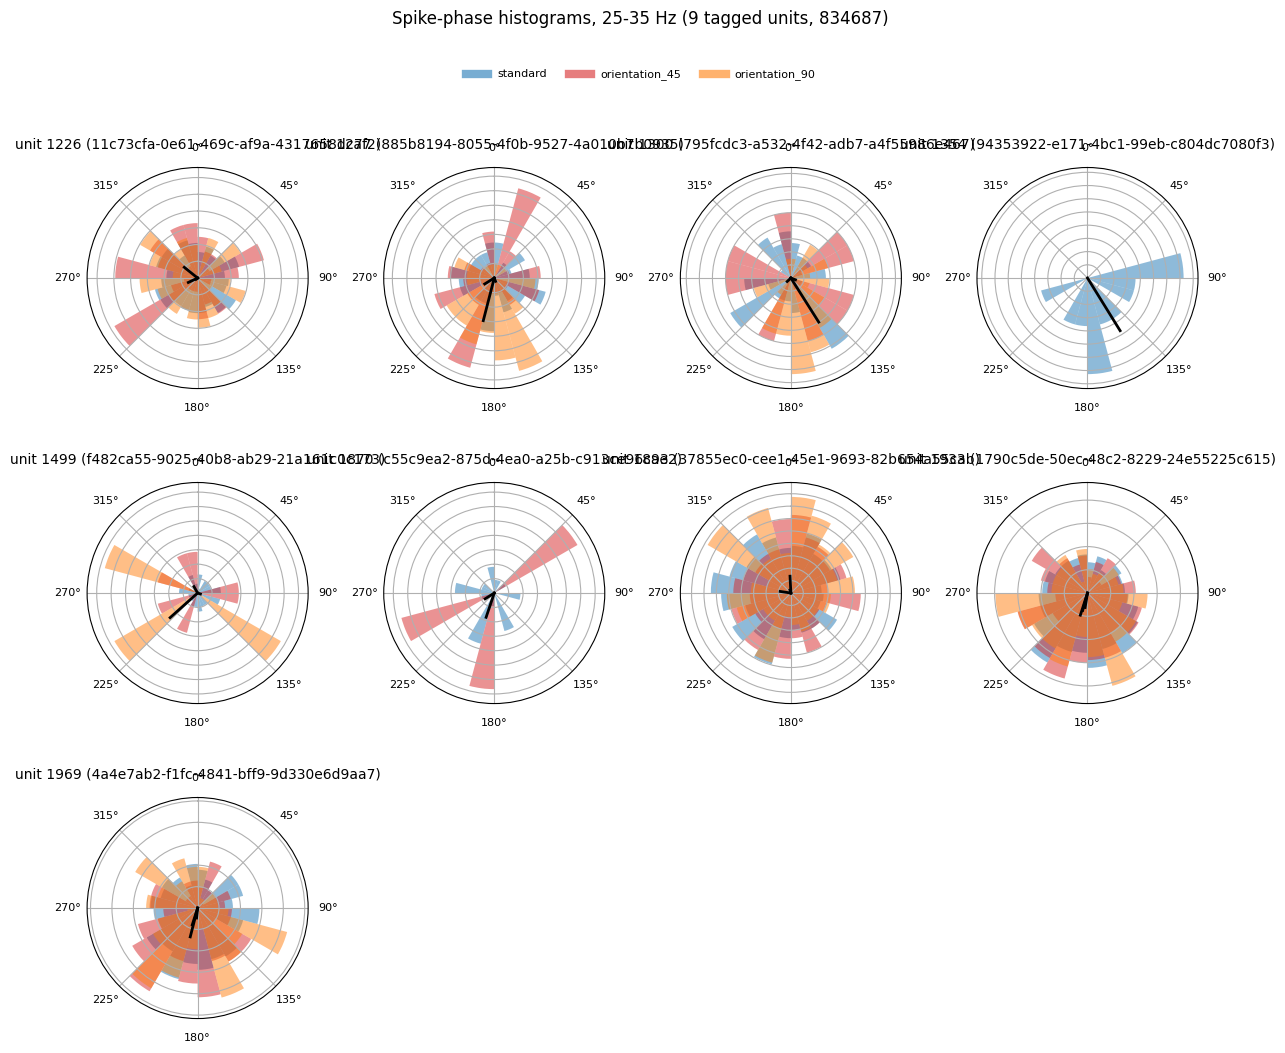

In [24]:
#@title Figure 2 · diagnostic — per-unit phase histograms (not in the assembled figure)
PHASE_CONDS = ["standard", "orientation_45", "orientation_90"]
N_PHASE_BINS = 24
PHASE_EDGES = np.linspace(-np.pi, np.pi, N_PHASE_BINS + 1)
PHASE_WIDTH = PHASE_EDGES[1] - PHASE_EDGES[0]


def polar_axis(ax):
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_yticklabels([])


def phase_histogram(ax, phases, color, resultant=None, preferred=None):
    """Density (not counts): standards contribute several times more spikes than deviants, and
    raw counts would make that difference dominate the shape comparison."""
    if len(phases) == 0:
        return 0.0
    counts, _ = np.histogram(phases, bins=PHASE_EDGES)
    density = counts / counts.sum()
    ax.bar(PHASE_EDGES[:-1], density, width=PHASE_WIDTH, align="edge",
           color=color, alpha=0.5, edgecolor="none")
    if preferred is not None and not np.isnan(preferred):
        # Arrow length scales with the resultant, so weak coupling reads as a short arrow even
        # when small samples give the histogram a spurious-looking peak.
        ax.plot([preferred, preferred], [0, resultant * density.max()], color="k", lw=2)
    return density.max()


units_to_plot = sorted({u for (u, c) in spike_phase_store if c in PHASE_CONDS})

if not units_to_plot:
    print("No tagged units with phase data for these conditions.")
else:
    ncols = min(4, len(units_to_plot))
    nrows = int(np.ceil(len(units_to_plot) / ncols))
    fig, axes = plt.subplots(nrows, ncols, subplot_kw={"projection": "polar"},
                             figsize=(3.0 * ncols, 3.3 * nrows), squeeze=False)
    axes = axes.ravel()

    for ax, u in zip(axes, units_to_plot):
        top = 0
        for cond in PHASE_CONDS:
            row = sfc_results[(sfc_results["unit_index"] == u) &
                              (sfc_results["condition"] == cond)]
            pref = np.radians(row["preferred_phase_deg"].iloc[0]) if not row.empty else np.nan
            R = row["resultant_length"].iloc[0] if not row.empty else np.nan
            top = max(top, phase_histogram(ax, spike_phase_store.get((u, cond), np.array([])),
                                           COND_COLORS[cond], R, pref))
        polar_axis(ax)
        ax.set_ylim(0, top * 1.15 if top > 0 else 1)
        names = sfc_results.loc[sfc_results["unit_index"] == u, "unit_name"]
        ax.set_title(f"unit {u} ({names.iloc[0] if len(names) else u})", pad=14)

    for ax in axes[len(units_to_plot):]:
        ax.axis("off")

    handles = [plt.Line2D([0], [0], color=COND_COLORS[c], lw=6, alpha=0.6) for c in PHASE_CONDS]
    fig.legend(handles, PHASE_CONDS, loc="upper center", ncol=len(PHASE_CONDS),
               frameon=False, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(f"Spike-phase histograms, {SFC_BAND[0]}-{SFC_BAND[1]} Hz "
                 f"({len(units_to_plot)} tagged units, {tag_subject})", y=1.07)
    plt.tight_layout()
    plt.show()

## 6.3 · Scaling to every animal

Each session is tagged independently, then contributes its tagged units and a control sample of
twice that size drawn at random from VISp units that were not directly light-activated.

Two layers of cache, because they have very different costs: the tagging screen reads
`spike_times` for every VISp unit in the session over the network and is the expensive step, so
it is cached on its own. Control sampling and phase pooling are cheap and cached separately —
changing `CONTROL_MULT` re-runs only the second layer.

In [25]:
#@title Tag, sample controls and pool phases across all sessions
# Stores PPC *per unit* as well as the pooled phases. The pooled value is one number with no
# variance attached, so it cannot support a test; per-unit values make the bars mean +/- SEM
# across units and allow standard-vs-oddball to be tested within unit.
POOL_GROUPS = {
    "standard": ["standard"],
    "oddball (45°+90°)": ["orientation_45", "orientation_90"],
}
CONTROL_MULT        = 2       # control units per tagged unit
CONTROL_RNG_OFFSET  = 1000
MIN_SPIKES_PER_UNIT = 30      # below this a per-unit PPC is too noisy to enter the summary

# Stimulus-aligned firing rate is collected in the same pass, so the rate panels describe every
# unit that entered the coupling analysis rather than just the example session.
STIM_PSTH_WINDOW = (-0.3, 0.6)
STIM_PSTH_BIN    = 0.01
STIM_PSTH_EDGES  = np.arange(STIM_PSTH_WINDOW[0], STIM_PSTH_WINDOW[1] + STIM_PSTH_BIN,
                             STIM_PSTH_BIN)
STIM_PSTH_TIME   = STIM_PSTH_EDGES[:-1] + STIM_PSTH_BIN / 2


def psth_around(spikes, onsets, edges):
    """Firing rate on a common grid, aligned to onsets."""
    if len(onsets) == 0:
        return np.zeros(len(edges) - 1)
    lo = np.searchsorted(spikes, onsets + edges[0])
    hi = np.searchsorted(spikes, onsets + edges[-1])
    chunks = [spikes[a:b] - o for a, b, o in zip(lo, hi, onsets) if b > a]
    if not chunks:
        return np.zeros(len(edges) - 1)
    counts, _ = np.histogram(np.concatenate(chunks), bins=edges)
    return counts / (len(onsets) * (edges[1] - edges[0]))
FORCE_RESCREEN      = False   # re-run the expensive per-unit tagging screen
FORCE_REPOOL        = False   # re-sample controls and re-pool phases only


def screen_cache_path(subject):
    return os.path.join(CACHE_DIR, f"{subject}_tagscreen.npz")


def pool_cache_path(subject):
    return os.path.join(CACHE_DIR,
                        f"{subject}_pool_{SFC_BAND[0]}-{SFC_BAND[1]}hz_x{CONTROL_MULT}_v3.npz")


def cached_tagging(nwb, subject, peak_rows):
    """(candidate units, tagged set) for a session, cached."""
    path = screen_cache_path(subject)
    if os.path.exists(path) and not FORCE_RESCREEN:
        with np.load(path) as z:
            return z["candidates"], set(z["tagged"].tolist())

    candidates, _ = candidate_units(nwb, peak_rows)
    if len(candidates) == 0:
        return candidates, set()
    print(f"    screening {len(candidates)} VISp units")
    screen, _ = screen_for_light_response(nwb, candidates, progress_every=100)
    tagged = set(tagged_from_screen(screen))
    np.savez_compressed(path, candidates=np.array(candidates),
                        tagged=np.array(sorted(tagged)))
    return candidates, tagged


def pool_phases(nwb, unit_list, peak_rows, edf, channel_map, group_col,
                windows_by_cond, neighbor_cache, phase_cache, t_lo, t_hi):
    """Pooled phases plus per-unit PPC, keyed by unit so conditions can be paired later."""
    spike_col = nwb.units["spike_times"]
    pooled = {name: [] for name in POOL_GROUPS}
    per_unit = {name: {} for name in POOL_GROUPS}
    psths = {name: [] for name in POOL_GROUPS}

    onsets_by_group = {}
    for name, conds in POOL_GROUPS.items():
        w = [windows_by_cond[c] for c in conds if len(windows_by_cond.get(c, []))]
        onsets_by_group[name] = np.concatenate(w)[:, 0] if w else np.array([])

    for u in unit_list:
        src, _ = phase_source(nwb, u, peak_rows, edf, channel_map, group_col,
                              neighbor_cache, phase_cache, t_lo, t_hi)
        if src is None:
            continue
        ts, phase = src
        spikes = np.sort(np.asarray(spike_col[int(u)]))
        for name in POOL_GROUPS:
            psths[name].append(psth_around(spikes, onsets_by_group[name], STIM_PSTH_EDGES))
        for name, conds in POOL_GROUPS.items():
            chunks = [ph for cond in conds
                      for ph, _ in [spike_phases_in_windows(
                          spikes, windows_by_cond.get(cond, np.empty((0, 2))), ts, phase)]
                      if len(ph)]
            if not chunks:
                continue
            ph_all = np.concatenate(chunks)
            pooled[name].append(ph_all)
            if len(ph_all) >= MIN_SPIKES_PER_UNIT:
                per_unit[name][int(u)] = ppc(ph_all)[0]

    pooled = {name: (np.concatenate(v) if v else np.array([])) for name, v in pooled.items()}
    psths = {name: (np.array(v) if v else np.zeros((0, len(STIM_PSTH_TIME))))
             for name, v in psths.items()}
    return pooled, per_unit, psths


def process_session(path, rng_seed):
    io, nwb = stream_nwb(DANDISET_ID, path)
    try:
        subject = str(nwb.subject.subject_id)
        units = nwb.units
        peak_rows, note = unit_peak_rows(units)
        if peak_rows is None:
            return subject, None, f"cannot place units: {note}"

        candidates, tagged = cached_tagging(nwb, subject, peak_rows)
        tagged_idx = sorted(tagged)
        if not tagged_idx:
            return subject, None, "no tagged units"

        # Only directly activated units are excluded. A unit suppressed by the light is very
        # likely a downstream target of the tagged interneurons, which makes it an informative
        # control rather than a contaminated one.
        control_pool = [i for i in candidates if i not in tagged]
        rng = np.random.default_rng(rng_seed)
        n_take = min(CONTROL_MULT * len(tagged_idx), len(control_pool))
        control_idx = sorted(rng.choice(control_pool, size=n_take, replace=False)) if n_take else []

        edf = nwb.electrodes.to_dataframe()
        group_col = next((c for c in ("group_name", "probe_name") if c in edf.columns), None)
        channel_map = lfp_channel_map(nwb)
        events = build_events(nwb, include_control=False)
        windows_by_cond = windows_by_condition(events)
        t_lo, t_hi = task_span(events)

        neighbor_cache, phase_cache = {}, {}
        args = (peak_rows, edf, channel_map, group_col, windows_by_cond,
                neighbor_cache, phase_cache, t_lo, t_hi)
        tagged_pooled, tagged_units_ppc, tagged_psth = pool_phases(nwb, tagged_idx, *args)
        control_pooled, control_units_ppc, control_psth = pool_phases(nwb, control_idx, *args)

        print(f"    tagged={len(tagged_idx)}, control={len(control_idx)} "
              f"(pool {len(control_pool)}), {len(phase_cache)} reference channels, "
              f"{t_hi - t_lo:.0f}s filtered")
        return subject, {"tagged": tagged_pooled, "control": control_pooled,
                         "tagged_ppc": tagged_units_ppc, "control_ppc": control_units_ppc,
                         "tagged_psth": tagged_psth, "control_psth": control_psth,
                         "n_tagged": len(tagged_idx), "n_control": len(control_idx)}, "ok"
    finally:
        io.close()


def save_pool(subject, result):
    flat = {"n_tagged": np.array(result["n_tagged"]),
            "n_control": np.array(result["n_control"])}
    for group in ("tagged", "control"):
        for name, arr in result[group].items():
            flat[f"{group}|{name}|phases"] = arr
        for name, d in result[f"{group}_ppc"].items():
            flat[f"{group}|{name}|units"] = np.array(sorted(d))
            flat[f"{group}|{name}|ppc"] = np.array([d[u] for u in sorted(d)])
        for name, arr in result[f"{group}_psth"].items():
            flat[f"{group}|{name}|psth"] = arr
    np.savez_compressed(pool_cache_path(subject), **flat)


def load_pool(subject):
    with np.load(pool_cache_path(subject)) as z:
        out = {"tagged": {}, "control": {}, "tagged_ppc": {}, "control_ppc": {},
               "tagged_psth": {}, "control_psth": {},
               "n_tagged": int(z["n_tagged"]), "n_control": int(z["n_control"])}
        for key in z.files:
            if key in ("n_tagged", "n_control"):
                continue
            group, name, field = key.split("|")
            if field == "phases":
                out[group][name] = z[key]
            elif field == "psth":
                out[f"{group}_psth"][name] = z[key]
        for group in ("tagged", "control"):
            for name in POOL_GROUPS:
                uk, pk = f"{group}|{name}|units", f"{group}|{name}|ppc"
                if uk in z.files:
                    out[f"{group}_ppc"][name] = dict(zip(z[uk].tolist(), z[pk].tolist()))
    return out


session_results = {}
for i, path in enumerate(STANDARD_SESSION_PATHS, start=1):
    subject = path.split("/")[0].replace("sub-", "")
    tag = f"[{i}/{len(STANDARD_SESSION_PATHS)}] {subject}"
    if os.path.exists(pool_cache_path(subject)) and not (FORCE_REPOOL or FORCE_RESCREEN):
        session_results[subject] = load_pool(subject)
        r = session_results[subject]
        print(f"{tag}: cached (tagged={r['n_tagged']}, control={r['n_control']})")
        continue
    try:
        subject, result, note = process_session(path, CONTROL_RNG_OFFSET + i)
        if result is None:
            print(f"{tag}: skipped -- {note}")
            continue
        save_pool(subject, result)
        session_results[subject] = result
        print(f"{tag}: tagged={result['n_tagged']}, control={result['n_control']}")
    except Exception as e:
        print(f"{tag}: FAILED -- {type(e).__name__}: {e}")

print(f"\n{len(session_results)} / {len(STANDARD_SESSION_PATHS)} sessions contributed")

ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/a7f50043-8883-4c0e-a956-2ff3e0f1b0ef/download/: 


    screening 147 VISp units
      100/147 units screened
      147/147 units screened
    tagged=9, control=18 (pool 138), 21 reference channels, 1579s filtered
[1/15] 834687: tagged=9, control=18


ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/9b9e8abe-7b43-47f1-b8e1-4114f87898a1/download/: 


    screening 59 VISp units
      59/59 units screened


ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/e597fc7d-a8e5-4a1f-833e-4eee1c139e35/download/: 


...

    screening 149 VISp units
      100/149 units screened
      149/149 units screened
    tagged=25, control=50 (pool 124), 30 reference channels, 1579s filtered
[13/15] 848387: tagged=25, control=50


ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/81807807-957a-40bf-9b81-52a8d560c8e6/download/: 


    screening 118 VISp units
      100/118 units screened
      118/118 units screened
    tagged=12, control=24 (pool 106), 18 reference channels, 1579s filtered
[14/15] 848390: tagged=12, control=24


ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/21988ae7-fce0-41f2-a2af-b6c2ddcd6e52/download/: 


    screening 151 VISp units
      100/151 units screened
      151/151 units screened
    tagged=19, control=38 (pool 132), 19 reference channels, 1579s filtered
[15/15] 820454: tagged=19, control=38

13 / 15 sessions contributed


In [26]:
#@title Pool across animals, build the per-unit table and test
from scipy.stats import mannwhitneyu

POP_N_PERM = 2000

# ── Pooled phases (for the polar panels) ────────────────────────────────────
pooled, n_units = {}, {}
for group in ("tagged", "control"):
    n_units[group] = sum(r[f"n_{group}"] for r in session_results.values())
    for name in POOL_GROUPS:
        chunks = [r[group][name] for r in session_results.values() if len(r[group].get(name, []))]
        pooled[(group, name)] = np.concatenate(chunks) if chunks else np.array([])

# ── Stimulus-aligned firing rate, every analysis unit across every session ──
group_psth = {}
for group in ("tagged", "control"):
    for name in POOL_GROUPS:
        chunks = [r[f"{group}_psth"][name] for r in session_results.values()
                  if len(r.get(f"{group}_psth", {}).get(name, []))]
        group_psth[(group, name)] = (np.vstack(chunks) if chunks
                                     else np.zeros((0, len(STIM_PSTH_TIME))))
        print(f"  PSTH {group:8s} {name:20s}: {group_psth[(group, name)].shape[0]} units")

# ── Per-unit PPC (for the bars and the tests) ───────────────────────────────
# A unit only enters if it has a PPC in BOTH conditions, so standard-vs-oddball is a genuine
# within-unit comparison rather than two different subsets of cells.
rows = []
for subject, r in session_results.items():
    for group in ("tagged", "control"):
        by_name = r[f"{group}_ppc"]
        names = list(POOL_GROUPS)
        common = set(by_name.get(names[0], {})) & set(by_name.get(names[1], {}))
        for u in sorted(common):
            rows.append({"subject": subject, "unit_index": u, "group": group,
                         "ppc_standard": by_name[names[0]][u],
                         "ppc_oddball": by_name[names[1]][u]})
unit_ppc = pd.DataFrame(rows)

print("=" * 78)
if unit_ppc.empty:
    print("No per-unit PPC available. Delete the pool cache and re-run with FORCE_REPOOL = True.")
else:
    summary = unit_ppc.groupby("group")[["ppc_standard", "ppc_oddball"]].agg(["mean", "sem", "count"])
    print(summary.round(5).to_string())

# ── Tests ───────────────────────────────────────────────────────────────────
# Within group, the same units contribute both numbers, so the paired test (Wilcoxon
# signed-rank) applies. Between groups the units are different cells, so the unpaired test
# (Mann-Whitney U) applies. There is no such thing as a paired U-test: the U statistic is the
# unpaired one, and signed-rank is its paired counterpart.
ppc_tests = {}

for group in ("tagged", "control"):
    sub = unit_ppc[unit_ppc["group"] == group]
    if len(sub) >= 5:
        stat, p = wilcoxon(sub["ppc_oddball"], sub["ppc_standard"])
        ppc_tests[("paired", group)] = {"n": len(sub), "stat": stat, "p": p,
                                        "test": "Wilcoxon signed-rank"}

for name, col in (("standard", "ppc_standard"), ("oddball", "ppc_oddball")):
    a = unit_ppc.loc[unit_ppc["group"] == "tagged", col]
    b = unit_ppc.loc[unit_ppc["group"] == "control", col]
    if len(a) >= 3 and len(b) >= 3:
        stat, p = mannwhitneyu(a, b, alternative="two-sided")
        ppc_tests[("unpaired", name)] = {"n_tagged": len(a), "n_control": len(b),
                                         "stat": stat, "p": p, "test": "Mann-Whitney U"}

print()
for key, t in ppc_tests.items():
    kind, label = key
    if kind == "paired":
        print(f"{label:8s} oddball vs standard  ({t['test']}, n={t['n']} units): "
              f"stat={t['stat']:.1f}, p={t['p']:.2e}")
    else:
        print(f"{label:8s} tagged vs control    ({t['test']}, "
              f"n={t['n_tagged']} vs {t['n_control']}): stat={t['stat']:.1f}, p={t['p']:.2e}")

# ── Pooled PPC and its uniform-phase null, kept for the polar panel captions ─
# With tens of thousands of spikes this null is extremely narrow, so a tiny PPC clears it
# easily. It answers "is this distribution non-uniform", not "is this effect large", and it
# does not model within-trial autocorrelation the way the per-session circular-shift null does.
RNG_POP = np.random.default_rng(0)


def uniform_null_ppc(n, n_perm=POP_N_PERM, rng=RNG_POP):
    if n < 2:
        return np.array([])
    return np.array([ppc(rng.uniform(-np.pi, np.pi, n))[0] for _ in range(n_perm)])


pop_stats = {}
for key, phases in pooled.items():
    val, R, pref = ppc(phases)
    null = uniform_null_ppc(len(phases))
    p = ((np.sum(null >= val) + 1) / (len(null) + 1)) if len(null) and not np.isnan(val) else np.nan
    pop_stats[key] = {"ppc": val, "R": R, "pref": pref, "p": p, "n_spikes": len(phases)}

print()
for (group, name), s in pop_stats.items():
    print(f"{group:8s} {name:20s}: pooled PPC={s['ppc']:+.4f} "
          f"pref={np.degrees(s['pref']):7.1f} deg n_spikes={s['n_spikes']:6d} p={s['p']:.4f}")


def angle_diff_deg(a, b):
    """Circular difference: a plain subtraction would report 350 deg vs 10 deg as 340."""
    return abs((np.degrees(a - b) + 180) % 360 - 180)


print()
for group in ("tagged", "control"):
    d = angle_diff_deg(pop_stats[(group, "oddball (45°+90°)")]["pref"],
                       pop_stats[(group, "standard")]["pref"])
    print(f"{group:8s}: preferred phase shifts {d:5.1f} deg standard -> oddball")

  PSTH tagged   standard            : 123 units
  PSTH tagged   oddball (45°+90°)   : 123 units
  PSTH control  standard            : 246 units
  PSTH control  oddball (45°+90°)   : 246 units
        ppc_standard                ppc_oddball               
                mean      sem count        mean      sem count
group                                                         
control      0.00642  0.00145   185     0.03880  0.00526   185
tagged       0.00552  0.00157    90     0.02777  0.00432    90

tagged   oddball vs standard  (Wilcoxon signed-rank, n=90 units): stat=877.0, p=2.48e-06
control  oddball vs standard  (Wilcoxon signed-rank, n=185 units): stat=2290.0, p=4.92e-18
standard tagged vs control    (Mann-Whitney U, n=90 vs 185): stat=7956.0, p=5.52e-01
oddball  tagged vs control    (Mann-Whitney U, n=90 vs 185): stat=7835.0, p=4.29e-01

tagged   standard            : pooled PPC=+0.0040 pref= -161.3 deg n_spikes= 55342 p=0.0005
tagged   oddball (45°+90°)   : pooled PPC=+0.0078

## 6.4 · Figure 2, assembled

Population panels use every tagged and control unit across all sessions. The trace, raster and
polar panels show two single units from the example session — one tagged, one not — each chosen
as the strongest oddball coupler of its group, so that the population effect can be seen in
individual cells rather than only in pooled histograms.

In [27]:
#@title Figure 2 · pick example units and gather trial-aligned data
# Everything the assembled figure needs from the example session, collected in one pass.
#
# Examples are chosen on evidence, not by hand: per-unit PPC is computed for the tagged units
# AND for a sample of non-tagged units, then the example of each kind is the one with the
# strongest oddball coupling. That is what makes the point the figure is arguing -- both
# populations are phase-modulated, the tagged one more so -- visible in single cells rather
# than only in the pooled histograms.

EXAMPLE_SESSION       = TAG_SESSION
N_CONTROL_FOR_EXAMPLE = None      # None = every non-tagged VISp unit (matches panel A)
RASTER_TRIALS         = 40        # trials drawn in the raster panel
POP_PSTH_WINDOW       = (-0.3, 0.6)
POP_PSTH_BIN          = 0.01
TRACE_PAD             = (0.35, 0.5)   # seconds shown before / after the example stimulus
EXAMPLE_RNG           = np.random.default_rng(7)

POP_PSTH_EDGES = np.arange(POP_PSTH_WINDOW[0], POP_PSTH_WINDOW[1] + POP_PSTH_BIN, POP_PSTH_BIN)
POP_PSTH_TIME  = POP_PSTH_EDGES[:-1] + POP_PSTH_BIN / 2

ODDBALL_ONLY = ["orientation_45", "orientation_90"]


def band_trace_windowed(es, lo, hi, t_lo, t_hi, col=0):
    """Raw and band-passed trace over a window, plus its phase."""
    ts, fs = series_time_base(es)
    i0, i1 = np.searchsorted(ts, [t_lo, t_hi])
    raw = (es.data[i0:i1, col] if es.data.ndim > 1 else es.data[i0:i1]).astype(np.float64)
    b, a = butter(4, [lo / (fs / 2), hi / (fs / 2)], btype="band")
    filtered = filtfilt(b, a, raw)
    return ts[i0:i1], raw, filtered, np.angle(hilbert(filtered))


def spikes_by_trial(spikes, onsets, window):
    """Spike times relative to each onset, one list per trial."""
    lo = np.searchsorted(spikes, onsets + window[0])
    hi = np.searchsorted(spikes, onsets + window[1])
    return [spikes[a:b] - o for a, b, o in zip(lo, hi, onsets)]


io, nwb = stream_nwb(DANDISET_ID, EXAMPLE_SESSION)
try:
    example_subject = str(nwb.subject.subject_id)
    units = nwb.units
    peak_rows, _ = unit_peak_rows(units)
    edf = nwb.electrodes.to_dataframe()
    group_col = next((c for c in ("group_name", "probe_name") if c in edf.columns), None)
    channel_map = lfp_channel_map(nwb)
    spike_col = units["spike_times"]

    candidates, tagged_set = cached_tagging(nwb, example_subject, peak_rows)
    tagged_idx = sorted(tagged_set)
    control_pool = [i for i in candidates if i not in tagged_set]
    control_idx = (sorted(control_pool) if N_CONTROL_FOR_EXAMPLE is None else
                   sorted(EXAMPLE_RNG.choice(
                       control_pool,
                       size=min(N_CONTROL_FOR_EXAMPLE, len(control_pool)), replace=False)))
    print(f"Session {example_subject}: {len(tagged_idx)} tagged, "
          f"{len(control_idx)} non-tagged screened for an example")

    events = build_events(nwb, include_control=False)
    windows_by_cond = windows_by_condition(events)
    t_lo, t_hi = task_span(events)
    std_windows = windows_by_cond["standard"]
    odd_windows = np.vstack([windows_by_cond[c] for c in ODDBALL_ONLY
                             if len(windows_by_cond.get(c, []))])

    neighbor_cache, phase_cache = {}, {}
    rows, spikes_cache, phase_of_unit = [], {}, {}

    for group, idx_list in (("tagged", tagged_idx), ("control", control_idx)):
        for u in idx_list:
            src, note = phase_source(nwb, u, peak_rows, edf, channel_map, group_col,
                                     neighbor_cache, phase_cache, t_lo, t_hi)
            if src is None:
                continue
            ts, phase = src
            spikes = np.sort(np.asarray(spike_col[int(u)]))
            spikes_cache[u] = spikes
            phase_of_unit[u] = (ts, phase)

            entry = {"unit_index": int(u), "group": group}
            for label, windows in (("standard", std_windows), ("oddball", odd_windows)):
                ph, _ = spike_phases_in_windows(spikes, windows, ts, phase)
                val, R, pref = ppc(ph)
                entry[f"ppc_{label}"] = val
                entry[f"n_{label}"] = len(ph)
                entry[f"pref_{label}"] = pref
            rows.append(entry)

    example_sfc = pd.DataFrame(rows)
    print(f"  {len(phase_cache)} distinct reference channels used")

    # Examples: strongest oddball coupling within each group, requiring enough spikes for the
    # estimate to mean anything.
    MIN_SPIKES_EXAMPLE = 100
    usable = example_sfc[example_sfc["n_oddball"] >= MIN_SPIKES_EXAMPLE]
    if usable.empty:
        usable = example_sfc
    picks = {}

    # Tagged example: the strongest coupler among the tagged units.
    tag_sub = usable[usable["group"] == "tagged"].sort_values("ppc_oddball", ascending=False)
    picks["tagged"] = int(tag_sub["unit_index"].iloc[0])
    tagged_ppc_value = float(tag_sub["ppc_oddball"].iloc[0])

    # Control example: NOT the strongest control. With ~10 tagged units and ~140 candidate
    # controls, the maximum of the larger sample almost always beats the maximum of the smaller
    # one for reasons of sample size alone, which would invert the comparison the figure makes.
    # A representative control -- the median among controls that are themselves clearly coupled
    # -- shows honestly that both populations are modulated, one more than the other.
    ctl_sub = usable[usable["group"] == "control"].sort_values("ppc_oddball")
    coupled = ctl_sub[ctl_sub["ppc_oddball"] > 0]
    ctl_sub = coupled if len(coupled) >= 3 else ctl_sub
    picks["control"] = int(ctl_sub["unit_index"].iloc[len(ctl_sub) // 2])

    for group in ("tagged", "control"):
        r = example_sfc[example_sfc["unit_index"] == picks[group]].iloc[0]
        note = "strongest of its group" if group == "tagged" else "median coupled control"
        print(f"  example {group}: unit {picks[group]} ({note}), "
              f"PPC oddball={r['ppc_oddball']:.4f}, standard={r['ppc_standard']:.4f}, "
              f"{int(r['n_oddball'])} oddball spikes")
    if example_sfc[example_sfc["group"] == "control"]["ppc_oddball"].max() > tagged_ppc_value:
        print("  note: some individual control units couple more strongly than any tagged unit; "
              "the group-level difference is the claim, not every single cell")

    # Raster of the two example units, oddball trials.
    raster = {}
    n_raster = min(RASTER_TRIALS, len(odd_windows))
    raster_onsets = odd_windows[:n_raster, 0]
    for group, u in picks.items():
        raster[group] = spikes_by_trial(spikes_cache[u], raster_onsets, POP_PSTH_WINDOW)

    # Band-passed trace around one oddball presentation, taken from the tagged example's own
    # reference channel, with both examples' spikes marked on it.
    tagged_u = picks["tagged"]
    peak = int(peak_rows[tagged_u])
    neighbor, _ = neighbor_cache[peak]
    series_name, col = channel_map[neighbor]
    es = nwb.processing["ecephys"]["LFP"].electrical_series[series_name]

    # Pick the oddball presentation during which the tagged example fired most.
    counts = window_counts(spikes_cache[tagged_u], odd_windows[:, 0], (0.0, 0.4))
    best_trial = int(np.argmax(counts))
    tr0, tr1 = odd_windows[best_trial]
    w0, w1 = tr0 - TRACE_PAD[0], tr1 + TRACE_PAD[1]
    trace_ts, trace_raw, trace_filt, trace_phase = band_trace_windowed(
        es, *SFC_BAND, w0, w1, col=col)

    trace_spikes = {}
    for group, u in picks.items():
        s = spikes_cache[u]
        trace_spikes[group] = s[(s >= w0) & (s <= w1)]

    # Spike phases per trial, for the phase raster.
    phase_raster = {}
    for group, u in picks.items():
        ts, phase = phase_of_unit[u]
        ph, trial = spike_phases_in_windows(spikes_cache[u], odd_windows, ts, phase)
        phase_raster[group] = [ph[trial == i] for i in range(len(odd_windows))]

    # Phases of the two examples, for the polar panels.
    example_phases = {}
    for group, u in picks.items():
        ts, phase = phase_of_unit[u]
        for label, windows in (("standard", std_windows), ("oddball", odd_windows)):
            ph, _ = spike_phases_in_windows(spikes_cache[u], windows, ts, phase)
            example_phases[(group, label)] = ph
finally:
    io.close()

fig2_example = {
    "subject": example_subject,
    "picks": picks,
    "sfc": example_sfc,
    "raster": raster,
    "phase_raster": phase_raster,
    "raster_onsets": raster_onsets,
    "trace": {"t": trace_ts - tr0, "raw": trace_raw, "filt": trace_filt,
              "phase": trace_phase, "stim": (0.0, tr1 - tr0)},
    "trace_spikes": {g: s - tr0 for g, s in trace_spikes.items()},
    "phases": example_phases,
    "n_tagged": len(tagged_idx),
    "n_control": len(control_idx),
}

print(f"\nTrace window: {trace_ts[-1] - trace_ts[0]:.2f} s around presentation {best_trial}, "
      f"reference channel {neighbor}")
print(f"Raster: {n_raster} oddball trials per example")
for group in ("tagged", "control"):
    print(f"Spikes on the example trace, {group}: {len(trace_spikes[group])}")

ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/a7f50043-8883-4c0e-a956-2ff3e0f1b0ef/download/: 


Session 834687: 9 tagged, 138 non-tagged screened for an example
  34 distinct reference channels used
  example tagged: unit 1277 (strongest of its group), PPC oddball=0.0729, standard=-0.0078, 100 oddball spikes
  example control: unit 1271 (median coupled control), PPC oddball=0.0374, standard=-0.0026, 157 oddball spikes
  note: some individual control units couple more strongly than any tagged unit; the group-level difference is the claim, not every single cell

Trace window: 1.22 s around presentation 7, reference channel 1426
Raster: 40 oddball trials per example
Spikes on the example trace, tagged: 5
Spikes on the example trace, control: 6


Saved ./figures/figure2_sfc.png
Saved ./figures/figure2_sfc.pdf


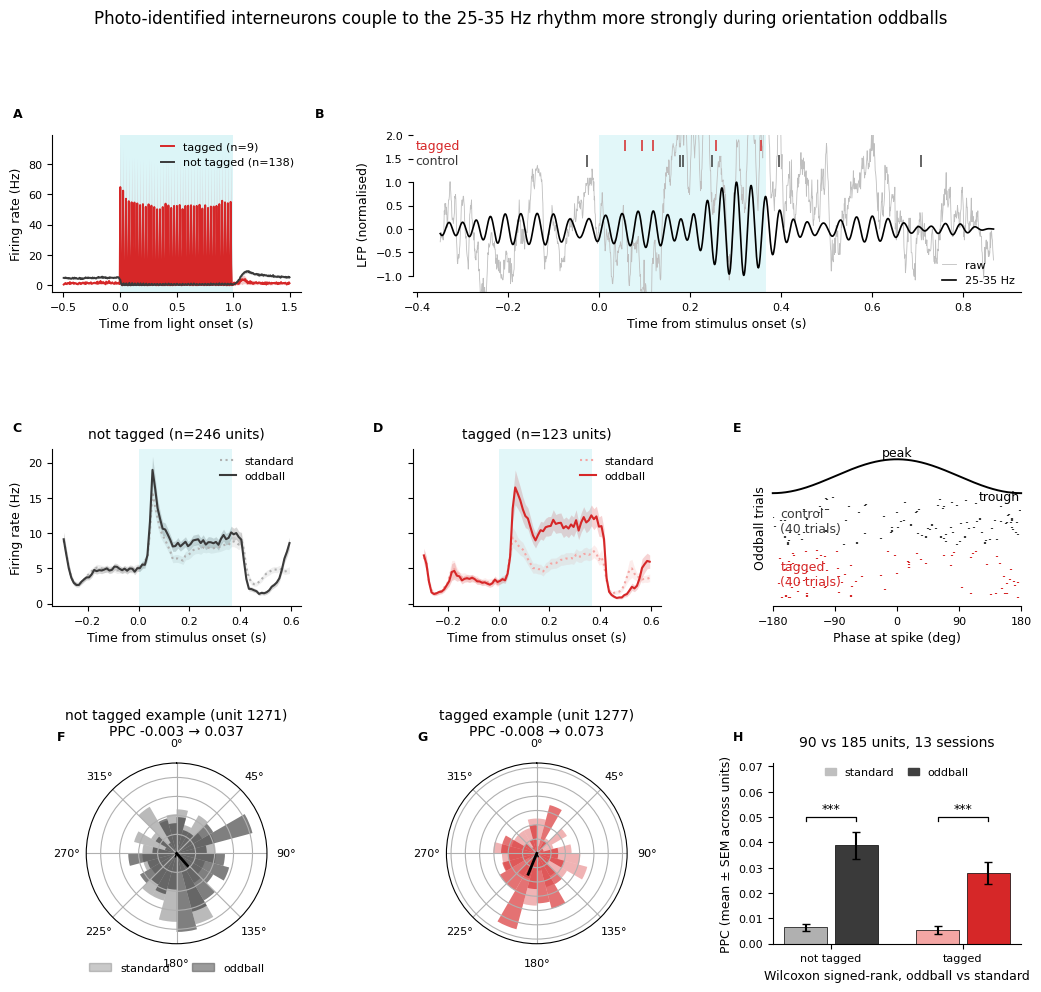

In [28]:
#@title Figure 2 · compose and save
#   row 1   optotagging response          |  band-passed LFP with example spikes
#   row 2   firing rate, not tagged  |  firing rate, tagged  |  phase raster (narrow)
#   row 3   polar, control example   |  polar, tagged example |  PPC standard vs oddball

TAGGED_COLOR   = "#d62728"
CONTROL_COLOR  = "#3a3a3a"
TAGGED_LIGHT   = "#f4a6a4"
CONTROL_LIGHT  = "#b0b0b0"
STIM_COLOR     = "tab:cyan"
RASTER_TRIALS  = 40

picks = fig2_example["picks"]
trace = fig2_example["trace"]


def mean_sem(arr):
    if len(arr) == 0:
        return None, None
    return arr.mean(axis=0), arr.std(axis=0) / np.sqrt(len(arr))


fig = plt.figure(figsize=(12.5, 10.5))
gs = fig.add_gridspec(3, 3, height_ratios=[1, 1, 1.15], hspace=0.95, wspace=0.45)

# ── A · optotagging response ────────────────────────────────────────────────
ax_opto = fig.add_subplot(gs[0, 0])
tagged_set = set(tagged_units)
for keep, color, label in [(True, TAGGED_COLOR, "tagged"), (False, CONTROL_COLOR, "not tagged")]:
    traces = np.array([v for (u, c), v in psths.items()
                       if c == "pulse_40hz" and (u in tagged_set) == keep])
    mean, sem = mean_sem(traces)
    if mean is None:
        continue
    ax_opto.plot(PSTH_TIME, mean, color=color, lw=1.4, label=f"{label} (n={len(traces)})")
    ax_opto.fill_between(PSTH_TIME, mean - sem, mean + sem, color=color, alpha=0.25, lw=0)
ax_opto.axvspan(0, 1, color=STIM_COLOR, alpha=0.15, lw=0)
ax_opto.set_xlabel("Time from light onset (s)")
ax_opto.set_ylabel("Firing rate (Hz)")
ax_opto.legend(frameon=False, loc="upper right", handlelength=1.2, borderaxespad=0.2)
strip_spines(ax_opto)

# ── B · band-passed LFP with example spikes ────────────────────────────────
ax_trace = fig.add_subplot(gs[0, 1:])
scale = np.abs(trace["filt"]).max() or 1.0
ax_trace.plot(trace["t"], trace["raw"] / scale, color="0.75", lw=0.6, label="raw")
ax_trace.plot(trace["t"], trace["filt"] / scale, color="k", lw=1.2,
              label=f"{SFC_BAND[0]}-{SFC_BAND[1]} Hz")
ax_trace.axvspan(*trace["stim"], color=STIM_COLOR, alpha=0.12, lw=0)

for group, color, offset in (("control", CONTROL_COLOR, 1.45), ("tagged", TAGGED_COLOR, 1.78)):
    st = fig2_example["trace_spikes"][group]
    if len(st):
        ax_trace.vlines(st, offset - 0.12, offset + 0.12, color=color, lw=1.1)
    ax_trace.annotate(group, xy=(0.005, offset), xycoords=("axes fraction", "data"),
                      ha="left", va="center", color=color)

ax_trace.set_ylim(-1.35, 2.0)
ax_trace.set_xlabel("Time from stimulus onset (s)")
ax_trace.set_ylabel("LFP (normalised)")
ax_trace.legend(frameon=False, loc="lower right", handlelength=1.2, borderaxespad=0.2)
strip_spines(ax_trace)
ax_trace.spines["left"].set_bounds(-1.0, 1.0)

# ── C, D · firing rate, every unit in the analysis ─────────────────────────
# Split by group and drawn on a shared y-axis, so the two are directly comparable.
rate_axes = {}
for col, (group, color, light) in enumerate(
        (("control", CONTROL_COLOR, CONTROL_LIGHT), ("tagged", TAGGED_COLOR, TAGGED_LIGHT))):
    ax = fig.add_subplot(gs[1, col], sharey=rate_axes.get("control"))
    rate_axes[group] = ax
    n_seen = 0
    for name, shade, style in ((list(POOL_GROUPS)[0], light, ":"),
                               (list(POOL_GROUPS)[1], color, "-")):
        mean, sem = mean_sem(group_psth[(group, name)])
        if mean is None:
            continue
        n_seen = max(n_seen, len(group_psth[(group, name)]))
        ax.plot(STIM_PSTH_TIME, mean, color=shade, lw=1.5, ls=style,
                label="standard" if style == ":" else "oddball")
        ax.fill_between(STIM_PSTH_TIME, mean - sem, mean + sem, color=shade, alpha=0.2, lw=0)
    ax.axvspan(0, STIM_DURATION, color=STIM_COLOR, alpha=0.12, lw=0)
    ax.set_xlabel("Time from stimulus onset (s)")
    ax.set_title(f"{'not tagged' if group == 'control' else 'tagged'} (n={n_seen} units)", pad=8)
    ax.legend(frameon=False, loc="upper right", handlelength=1.4, borderaxespad=0.2)
    strip_spines(ax)
rate_axes["control"].set_ylabel("Firing rate (Hz)")
rate_axes["tagged"].tick_params(labelleft=False)

# ── E · phase raster ───────────────────────────────────────────────────────
# Narrow on purpose: a wide axis flattens the reference cycle and makes peak and trough hard to
# read, which is the whole point of plotting spikes against phase rather than time.
ax_raster = fig.add_subplot(gs[1, 2])
row = 0
row_labels = []
for group, color in (("control", CONTROL_COLOR), ("tagged", TAGGED_COLOR)):
    trials = [t for t in fig2_example["phase_raster"][group] if len(t)][:RASTER_TRIALS]
    start_row = row
    for phases in trials:
        ax_raster.vlines(np.degrees(phases), row, row + 0.9, color=color, lw=1.6)
        row += 1
    row_labels.append((group, color, (start_row + row) / 2, len(trials)))
    row += 4

if row > 0:
    x = np.linspace(-180, 180, 400)
    amp = 0.16 * row
    ax_raster.plot(x, -3 - amp - amp * np.cos(np.radians(x)), color="k", lw=1.4, clip_on=False)
    ax_raster.annotate("peak", xy=(0, -3 - 2 * amp), ha="center", va="bottom")
    ax_raster.annotate("trough", xy=(178, -3 - 0.15 * amp), ha="right", va="top")

for group, color, ypos, n in row_labels:
    ax_raster.annotate(f"{group}\n({n} trials)", xy=(0.03, ypos),
                       xycoords=("axes fraction", "data"),
                       ha="left", va="center", color=color)

ax_raster.set_xlim(-180, 180)
ax_raster.set_xticks([-180, -90, 0, 90, 180])
ax_raster.set_ylim(row + 3, -3 - 2.6 * (0.16 * row))
ax_raster.set_xlabel("Phase at spike (deg)")
ax_raster.set_ylabel("Oddball trials")
ax_raster.set_yticks([])
strip_spines(ax_raster)
ax_raster.spines["left"].set_visible(False)

# ── F, G · polar histograms of the two examples ────────────────────────────
polar_axes = {}
for col, (group, color) in enumerate((("control", CONTROL_COLOR), ("tagged", TAGGED_COLOR))):
    ax = fig.add_subplot(gs[2, col], projection="polar")
    polar_axes[group] = ax
    top = 0
    for label, alpha in (("standard", 0.35), ("oddball", 0.65)):
        phases = fig2_example["phases"][(group, label)]
        if len(phases) == 0:
            continue
        counts, _ = np.histogram(phases, bins=PHASE_EDGES)
        density = counts / counts.sum()
        top = max(top, density.max())
        ax.bar(PHASE_EDGES[:-1], density, width=PHASE_WIDTH, align="edge",
               color=color, alpha=alpha, edgecolor="none")
        val, R, pref = ppc(phases)
        if not np.isnan(pref):
            ax.plot([pref, pref], [0, R * density.max()], color="k",
                    lw=2.0 if label == "oddball" else 1.0)
    polar_axis(ax)
    ax.set_ylim(0, top * 1.15 if top > 0 else 1)
    r = fig2_example["sfc"]
    r = r[r["unit_index"] == picks[group]].iloc[0]
    ax.set_title(f"{'not tagged' if group == 'control' else 'tagged'} example "
                 f"(unit {picks[group]})\nPPC {r['ppc_standard']:.3f} → {r['ppc_oddball']:.3f}",
                 pad=20)

handles = [plt.Rectangle((0, 0), 1, 1, color="0.4", alpha=a) for a in (0.35, 0.65)]
polar_axes["control"].legend(handles, ["standard", "oddball"], frameon=False,
                             loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=2)

# ── H · PPC, standard vs oddball within each group ─────────────────────────
# Grouped by cell class rather than by condition, because the comparison that carries a paired
# test is standard vs oddball within the same units. Tagged vs control is between different
# cells and, at this sample size, does not separate -- the effect the panel shows is the
# oddball increase, present in both classes.
ax_ppc = fig.add_subplot(gs[2, 2])
positions, heights, errors, colors = [], [], [], []
for i, (group, color, light) in enumerate(
        (("control", CONTROL_COLOR, CONTROL_LIGHT), ("tagged", TAGGED_COLOR, TAGGED_LIGHT))):
    for j, (col, shade) in enumerate((("ppc_standard", light), ("ppc_oddball", color))):
        vals = unit_ppc.loc[unit_ppc["group"] == group, col]
        positions.append(i * 2.6 + j)
        heights.append(vals.mean() if len(vals) else np.nan)
        errors.append(vals.sem() if len(vals) > 1 else 0.0)
        colors.append(shade)

ax_ppc.bar(positions, heights, yerr=errors, capsize=3, color=colors,
           edgecolor="k", linewidth=0.5, width=0.85)

top = max(h + e for h, e in zip(heights, errors) if not np.isnan(h))
for i, group in enumerate(("control", "tagged")):
    t = ppc_tests.get(("paired", group))
    if t is None:
        continue
    x0, x1 = i * 2.6, i * 2.6 + 1
    y = top * 1.10
    ax_ppc.plot([x0, x0, x1, x1], [y, y * 1.03, y * 1.03, y], color="k", lw=0.9)
    ax_ppc.text((x0 + x1) / 2, y * 1.05, sig_stars(t["p"]), ha="center", va="bottom")

ax_ppc.set_ylim(0, top * 1.62)
ax_ppc.set_xticks([0.5, 3.1])
ax_ppc.set_xticklabels(["not tagged", "tagged"])
ax_ppc.set_ylabel("PPC (mean ± SEM across units)")
n_t = int((unit_ppc["group"] == "tagged").sum())
n_c = int((unit_ppc["group"] == "control").sum())
ax_ppc.set_title(f"{n_t} vs {n_c} units, {len(session_results)} sessions", pad=12)
ax_ppc.set_xlabel("Wilcoxon signed-rank, oddball vs standard")
strip_spines(ax_ppc)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ("0.75", "0.25")]
ax_ppc.legend(handles, ["standard", "oddball"], frameon=False, ncol=2,
              loc="upper center", bbox_to_anchor=(0.5, 1.0), handlelength=1.0,
              columnspacing=1.2, borderaxespad=0.0)

# ── labels ──────────────────────────────────────────────────────────────────
for ax, letter in [(ax_opto, "A"), (ax_trace, "B"), (rate_axes["control"], "C"),
                   (rate_axes["tagged"], "D"), (ax_raster, "E"),
                   (polar_axes["control"], "F"), (polar_axes["tagged"], "G"), (ax_ppc, "H")]:
    ax.text(-0.16, 1.18, letter, transform=ax.transAxes,
            fontweight="bold", va="top", ha="left")

fig.suptitle(f"Photo-identified interneurons couple to the {SFC_BAND[0]}-{SFC_BAND[1]} Hz "
             f"rhythm more strongly during orientation oddballs", y=1.0)

for ext in ("png", "pdf"):
    out = os.path.join(FIGURE_DIR, f"figure2_sfc.{ext}")
    fig.savefig(out, dpi=300, bbox_inches="tight")
    print(f"Saved {out}")
plt.show()

In [29]:
#@title Figure 2 provenance
print(f"Sessions contributing : {len(session_results)} / {len(STANDARD_SESSION_PATHS)}")
print(f"Genotype              : SST-IRES-Cre;Ai32 (ChR2 in somatostatin interneurons)")
print(f"Tagging criterion     : activated by {' or '.join(TRUSTED_TAG_CONDITIONS)}, "
      f"FDR q<{ALPHA_TAG}, evoked/baseline >= {MIN_RATIO}")
print(f"Baseline / evoked     : {BASELINE_WINDOW} / {EVOKED_WINDOW} s around light onset")
print(f"Control group         : {CONTROL_MULT}x random VISp units, not directly light-activated")
print(f"Band                  : {SFC_BAND[0]}-{SFC_BAND[1]} Hz")
print(f"Phase reference       : nearest neighbour LFP channel, own peak channel excluded")
print(f"Coupling metric       : PPC (spike-count unbiased)")
print(f"Per-session null      : per-trial circular shift, {SFC_N_PERM} permutations")
print(f"Population null       : i.i.d. uniform phase, {POP_N_PERM} draws")
print(f"Example session       : {fig2_example['subject']}, "
      f"tagged unit {fig2_example['picks']['tagged']}, "
      f"control unit {fig2_example['picks']['control']}")
print()
for subject, r in sorted(session_results.items()):
    print(f"  {subject}: {r['n_tagged']:2d} tagged, {r['n_control']:2d} control")

Sessions contributing : 13 / 15
Genotype              : SST-IRES-Cre;Ai32 (ChR2 in somatostatin interneurons)
Tagging criterion     : activated by pulse_5hz or pulse_40hz, FDR q<0.01, evoked/baseline >= 2.0
Baseline / evoked     : (-0.6, -0.1) / (0.0, 1.0) s around light onset
Control group         : 2x random VISp units, not directly light-activated
Band                  : 25-35 Hz
Phase reference       : nearest neighbour LFP channel, own peak channel excluded
Coupling metric       : PPC (spike-count unbiased)
Per-session null      : per-trial circular shift, 200 permutations
Population null       : i.i.d. uniform phase, 2000 draws
Example session       : 834687, tagged unit 1277, control unit 1271

  820454: 19 tagged, 38 control
  830794: 21 tagged, 42 control
  830846:  9 tagged, 18 control
  830847:  3 tagged,  6 control
  830848:  7 tagged, 14 control
  830851:  1 tagged,  2 control
  830852:  4 tagged,  8 control
  832691:  2 tagged,  4 control
  834686:  6 tagged, 12 control
 

## Appendix A · optotagging exploration

Not needed to reproduce Figure 2. These are the cells used to work out where the optotagging
metadata lives — nothing in the file is labelled "opto", the blocks are named after their
waveform (`raised_cosine`, `5 hz pulse train`, `40 hz pulse train`), and `Zebra_presentations`
turns out to be a visual movie block rather than a light block.

In [30]:
#@title Inventory units and opto metadata across sessions (slow, optional)
RUN_UNIT_INVENTORY = False   #@param {type:"boolean"}

OPTO_KEYWORDS = ("opto", "tag", "laser", "light", "led", "ogen")

if not RUN_UNIT_INVENTORY:
    print("Skipped. Set RUN_UNIT_INVENTORY = True to inventory every session.")
else:
    def opto_hits(names):
        return [n for n in names if any(w in str(n).lower() for w in OPTO_KEYWORDS)]

    rows = []
    for i, path in enumerate(STANDARD_SESSION_PATHS, start=1):
        try:
            io, nwb = stream_nwb(DANDISET_ID, path)
            try:
                subject = str(nwb.subject.subject_id)
                units = getattr(nwb, "units", None)
                peak_rows, note = unit_peak_rows(units) if units is not None else (None, "no units")
                n_visp = np.nan
                if peak_rows is not None:
                    locs = unit_locations_from_rows(nwb, peak_rows)
                    n_visp = int(sum(is_visp(l) for l in locs))
                rows.append({
                    "subject": subject,
                    "genotype": str(getattr(nwb.subject, "genotype", "") or "unknown"),
                    "n_units": len(units) if units is not None else 0,
                    "n_visp": n_visp,
                    "opto_intervals": ",".join(opto_hits(list(nwb.intervals.keys()))),
                    "interval_tables": len(nwb.intervals),
                })
                print(f"[{i}] {subject}: {rows[-1]['n_units']} units, {n_visp} in VISp")
            finally:
                io.close()
        except Exception as e:
            print(f"[{i}] FAILED {path}: {type(e).__name__}: {e}")

    units_overview = pd.DataFrame(rows)
    print()
    print(units_overview.to_string(index=False))

Skipped. Set RUN_UNIT_INVENTORY = True to inventory every session.


In [31]:
#@title Inspect the stimulus tables of one session (optional)
RUN_TABLE_INSPECTION = False   #@param {type:"boolean"}

if not RUN_TABLE_INSPECTION:
    print("Skipped. Set RUN_TABLE_INSPECTION = True to dump the interval tables.")
else:
    io, nwb = stream_nwb(DANDISET_ID, STANDARD_SESSION_PATHS[0])
    try:
        print(f"Session {nwb.subject.subject_id}")
        print(f"Interval tables: {list(nwb.intervals.keys())}\n")
        for name in nwb.intervals:
            df = nwb.intervals[name].to_dataframe()
            dur = (df["stop_time"] - df["start_time"]).to_numpy()
            print(f"--- {name}: {len(df)} trials, median {np.median(dur):.4f} s, "
                  f"spans {df['start_time'].min():.1f}-{df['stop_time'].max():.1f} s")
            for col in df.columns:
                if col in ("start_time", "stop_time", "tags", "timeseries"):
                    continue
                vals = pd.unique(df[col])
                print(f"    {col}: {len(vals)} unique -> {list(vals[:6])}")
            print()
        print(f"Units columns: {list(nwb.units.colnames)}")
    finally:
        io.close()

Skipped. Set RUN_TABLE_INSPECTION = True to dump the interval tables.


## Appendix B · session discovery

Not needed to reproduce the figure. This regenerates the full session inventory of the dandiset,
which is how `STANDARD_SESSION_PATHS` was chosen in the first place, and is the cell to re-run
when deciding whether to refresh the frozen list. It streams every ecephys session, so it is slow.

In [32]:
#@title Inventory every ecephys session (slow, optional)
RUN_DISCOVERY = False   #@param {type:"boolean"}

PLACEHOLDER_LOCATIONS = {"void", "none", "unknown", "n/a", "root", ""}
BLOCK_KEYWORDS = {
    "standard": ["standard"],
    "sensorimotor": ["sensory-motor", "sensorimotor"],
    "sequence": ["sequence"],
    "duration": ["duration"],
}
DISCOVERY_CACHE = os.path.join(CACHE_DIR, "sessions_overview.csv")


def strip_layer(location):
    """Area name without the layer suffix.

    Hippocampal fields are an explicit exception: the digit in CA1/CA2/CA3 is part of the area
    name, not a layer.
    """
    if re.fullmatch(r"CA[123]", location):
        return location
    return re.sub(r"[0-9/]+[ab]?$", "", location)


if not RUN_DISCOVERY:
    print("Discovery skipped. Set RUN_DISCOVERY = True to rebuild the session inventory.")
elif os.path.exists(DISCOVERY_CACHE):
    sessions_df = pd.read_csv(DISCOVERY_CACHE)
    print(f"Loaded {len(sessions_df)} sessions from {DISCOVERY_CACHE}")
else:
    with DandiAPIClient() as client:
        assets = [a.path for a in client.get_dandiset(DANDISET_ID, "draft").get_assets()
                  if a.path.endswith(".nwb") and "ecephys" in a.path]
    print(f"Found {len(assets)} ecephys sessions\n")

    rows = []
    for i, path in enumerate(assets, start=1):
        try:
            io, nwb = stream_nwb(DANDISET_ID, path)
            try:
                blocks = sorted({name for key, words in BLOCK_KEYWORDS.items()
                                 for name in [key]
                                 for interval in nwb.intervals
                                 if any(w in interval.lower() for w in words)})
                have_lfp = lfp_channel_map(nwb)
                edf = nwb.electrodes.to_dataframe().reset_index()
                edf = edf.rename(columns={edf.columns[0]: "electrode_id"})
                edf["electrode_id"] = edf["electrode_id"].astype(int)
                edf_lfp = edf[edf["electrode_id"].isin(have_lfp) &
                              ~edf["location"].astype(str).str.lower().isin(PLACEHOLDER_LOCATIONS)]
                areas = sorted(edf_lfp["location"].astype(str).unique())
                rows.append({
                    "subject_id": str(nwb.subject.subject_id), "path": path,
                    "blocks": ",".join(blocks),
                    "n_lfp_electrodes": len(edf_lfp),
                    "areas_with_lfp": ",".join(areas),
                    "regions_with_lfp": ",".join(sorted({strip_layer(a) for a in areas})),
                })
                print(f"[{i}/{len(assets)}] {rows[-1]['subject_id']}: "
                      f"blocks=[{rows[-1]['blocks']}] {len(edf_lfp)} LFP channels")
            finally:
                io.close()
        except Exception as e:
            print(f"[{i}/{len(assets)}] FAILED {path}: {type(e).__name__}: {e}")

    sessions_df = pd.DataFrame(rows)
    sessions_df.to_csv(DISCOVERY_CACHE, index=False)
    print(f"\nSaved {DISCOVERY_CACHE}")

Discovery skipped. Set RUN_DISCOVERY = True to rebuild the session inventory.
